In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import numpy as np
from scipy.stats import normaltest
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from sklearn.base import clone

# Membuat variabel nama file
file = "household_power_consumption.csv"

# Membaca dataset
df = pd.read_csv(file)

# Menampilkan DataFrame
df.head()

,index,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,0,1/1/07,0:00:00,2.58,0.136,241.97,10.6,0,0,0.0
1,1,1/1/07,0:01:00,2.552,0.1,241.75,10.4,0,0,0.0
2,2,1/1/07,0:02:00,2.55,0.1,241.64,10.4,0,0,0.0
3,3,1/1/07,0:03:00,2.55,0.1,241.71,10.4,0,0,0.0
4,4,1/1/07,0:04:00,2.554,0.1,241.98,10.4,0,0,0.0


# Tipe Data

In [2]:
df.dtypes

index                      int64
Date                         str
Time                         str
Global_active_power          str
Global_reactive_power        str
Voltage                      str
Global_intensity             str
Sub_metering_1               str
Sub_metering_2               str
Sub_metering_3           float64
dtype: object

Dari pengecekan tipe data kolom Global_active_power, Global_reactive_power, Voltage, Global_intensity, Sub_metering_1, dan Sub_metering_2 bertipe string. Sehingga perlu dilakukan perubahan tipe data dari string menjadi float.

# Statistik Deskriptif

In [3]:
df.describe()

,index,Sub_metering_3
count,260640.000000,256869.000000
mean,130319.500000,5.831825
std,75240.431418,8.186709
min,0.000000,0.000000
25%,65159.750000,0.000000
50%,130319.500000,0.000000
75%,195479.250000,17.000000
max,260639.000000,20.000000


# Missing Value

In [4]:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing (%)': round(df.isnull().mean() * 100,2)
})

missing

,Missing Count,Missing (%)
index,0,0.00
Date,0,0.00
Time,0,0.00
Global_active_power,0,0.00
Global_reactive_power,0,0.00
Voltage,0,0.00
Global_intensity,0,0.00
Sub_metering_1,0,0.00
Sub_metering_2,0,0.00
Sub_metering_3,3771,1.45


Berdasarkan hasil pemeriksaan awal, missing value hanya terdeteksi pada kolom Sub_metering_3. Namun, hasil ini belum dapat dijadikan kesimpulan akhir karena beberapa kolom masih memiliki tipe data yang belum sesuai.

Oleh karena itu, pemeriksaan missing value perlu dilakukan kembali setelah proses konversi tipe data. Hal ini bertujuan untuk memastikan tidak terdapat nilai kosong sebelumnya tidak teridentifikasi sebagai missing value oleh Pandas.

# Duplicated

In [5]:
# Check duplicate rows
print("Total Duplicate Rows:", df.duplicated().sum())
print("Duplicate Percentage:",
      round(df.duplicated().mean() * 100, 2), "%")

Total Duplicate Rows: 0
Duplicate Percentage: 0.0 %


Tidak terdapat baris yang duplicated pada dataset ini

# Konsistensi

In [6]:
# Memilih seluruh kolom kategorikal
cat_cols = df.select_dtypes(
    include=['object', 'string', 'category']
).columns

# Menampilkan nilai unik beserta frekuensinya
for col in cat_cols:
    print(f"\nKolom: {col}")
    print(df[col].value_counts(dropna=False))


Kolom: Date
Date
1/1/07       1440
2/1/07       1440
3/1/07       1440
4/1/07       1440
5/1/07       1440
             ... 
26/6/2007    1440
27/6/2007    1440
28/6/2007    1440
29/6/2007    1440
30/6/2007    1440
Name: count, Length: 181, dtype: int64

Kolom: Time
Time
0:00:00     181
0:01:00     181
0:02:00     181
0:03:00     181
0:04:00     181
           ... 
23:55:00    181
23:56:00    181
23:57:00    181
23:58:00    181
23:59:00    181
Name: count, Length: 1440, dtype: int64

Kolom: Global_active_power
Global_active_power
?        3771
0.216    2975
0.218    2828
0.22     2471
0.214    2150
         ... 
6.914       1
5.912       1
7.022       1
4.592       1
6.152       1
Name: count, Length: 3585, dtype: int64

Kolom: Global_reactive_power
Global_reactive_power
0        65262
?         3771
0.1       2880
0.106     2832
0.104     2807
         ...  
0.946        1
0.902        1
1.046        1
1.148        1
1.054        1
Name: count, Length: 414, dtype: int64

Kolom: Volta

Seletah dilakukan pengecekan konsistensi, terdapat nilai invalid berupa nilai tanda tanya (?) pada kolom Global_active_power, Global_reactive_power, Voltage, Global_intensity, Sub_metering_1, dan Sub_metering_2. Sehingga perlu dilakukan penanganan saat merubah tipe data.

# Encoding

In [7]:
df_encoded = df.copy()

# Menyimpan encoder tiap kolom
encoders = {}

# Label Encoding seluruh kolom
for col in df_encoded.columns:

    le = LabelEncoder()

    df_encoded[col] = le.fit_transform(
        df_encoded[col]
        .astype("string")
        .fillna("__MISSING__")
    )

    encoders[col] = le

# Menampilkan hasil
display(df_encoded.head())

# Mengecek tipe data
print(df_encoded.dtypes)

,index,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,0,0,0,1252,46,1534,11,0,0,0
1,1,0,1,1238,28,1512,10,0,0,0
2,111112,0,2,1237,28,1501,10,0,0,0
3,182863,0,3,1237,28,1508,10,0,0,0
4,193974,0,4,1239,28,1535,10,0,0,0


index                    int64
Date                     int64
Time                     int64
Global_active_power      int64
Global_reactive_power    int64
Voltage                  int64
Global_intensity         int64
Sub_metering_1           int64
Sub_metering_2           int64
Sub_metering_3           int64
dtype: object


# Outlier

In [8]:
# Memilih kolom numerik
numeric = df_encoded.select_dtypes(include='number')

 
# Menghitung kuartil
Q1 = numeric.quantile(0.25)
Q3 = numeric.quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Mendeteksi outlier
outlier = (numeric < lower) | (numeric > upper)

# Membuat tabel ringkasan
outlier_summary = pd.DataFrame({
    'Total Outlier': outlier.sum(),
    'Persentase (%)': (outlier.mean() * 100).round(2)
})

outlier_summary

,Total Outlier,Persentase (%)
index,0,0.00
Date,0,0.00
Time,0,0.00
Global_active_power,15561,5.97
Global_reactive_power,7711,2.96
Voltage,522,0.20
Global_intensity,0,0.00
Sub_metering_1,26970,10.35
Sub_metering_2,37615,14.43
Sub_metering_3,0,0.00


Terdapat outlier pada kolom Global_active_power, Global_reactive_power, Sub_metering_1, dan Sub_metering_2. Perlu dilakukan pengecekan kembali setelah tipe data sudah diatasi.

# Normalitas

In [9]:
# Memilih kolom numerik
numeric_cols = df_encoded.select_dtypes(
    include='number'
).columns

results = []

for col in numeric_cols:

    # Konversi menjadi numerik dan hilangkan missing value
    data = pd.to_numeric(
        df_encoded[col], errors='coerce'
    ).dropna()

    if len(data) < 8 or data.nunique() < 2:
        results.append({
            'Kolom': col,
            'P-Value': None,
            'Kesimpulan': 'Tidak dapat diuji'
        })
        continue

    # Uji normalitas
    stat, p_value = normaltest(data)

    results.append({
        'Kolom': col,
        'P-Value': round(p_value,4),
        'Kesimpulan': (
            'Normal (tidak ditolak)'
            if p_value > 0.05
            else 'Tidak Normal'
        )
    })

# Membuat dataframe hasil
normality_summary = pd.DataFrame(results)

normality_summary

,Kolom,P-Value,Kesimpulan
0,index,0.0,Tidak Normal
1,Date,0.0,Tidak Normal
2,Time,0.0,Tidak Normal
3,Global_active_power,0.0,Tidak Normal
4,Global_reactive_power,0.0,Tidak Normal
5,Voltage,0.0,Tidak Normal
6,Global_intensity,0.0,Tidak Normal
7,Sub_metering_1,0.0,Tidak Normal
8,Sub_metering_2,0.0,Tidak Normal
9,Sub_metering_3,0.0,Tidak Normal


Semua kolom tidak terdapat kolom yang terdistribusi normal. Perlu dilakukan pengecekan ulang setelah memperbaiki tipe data

# EDA

## Univariat

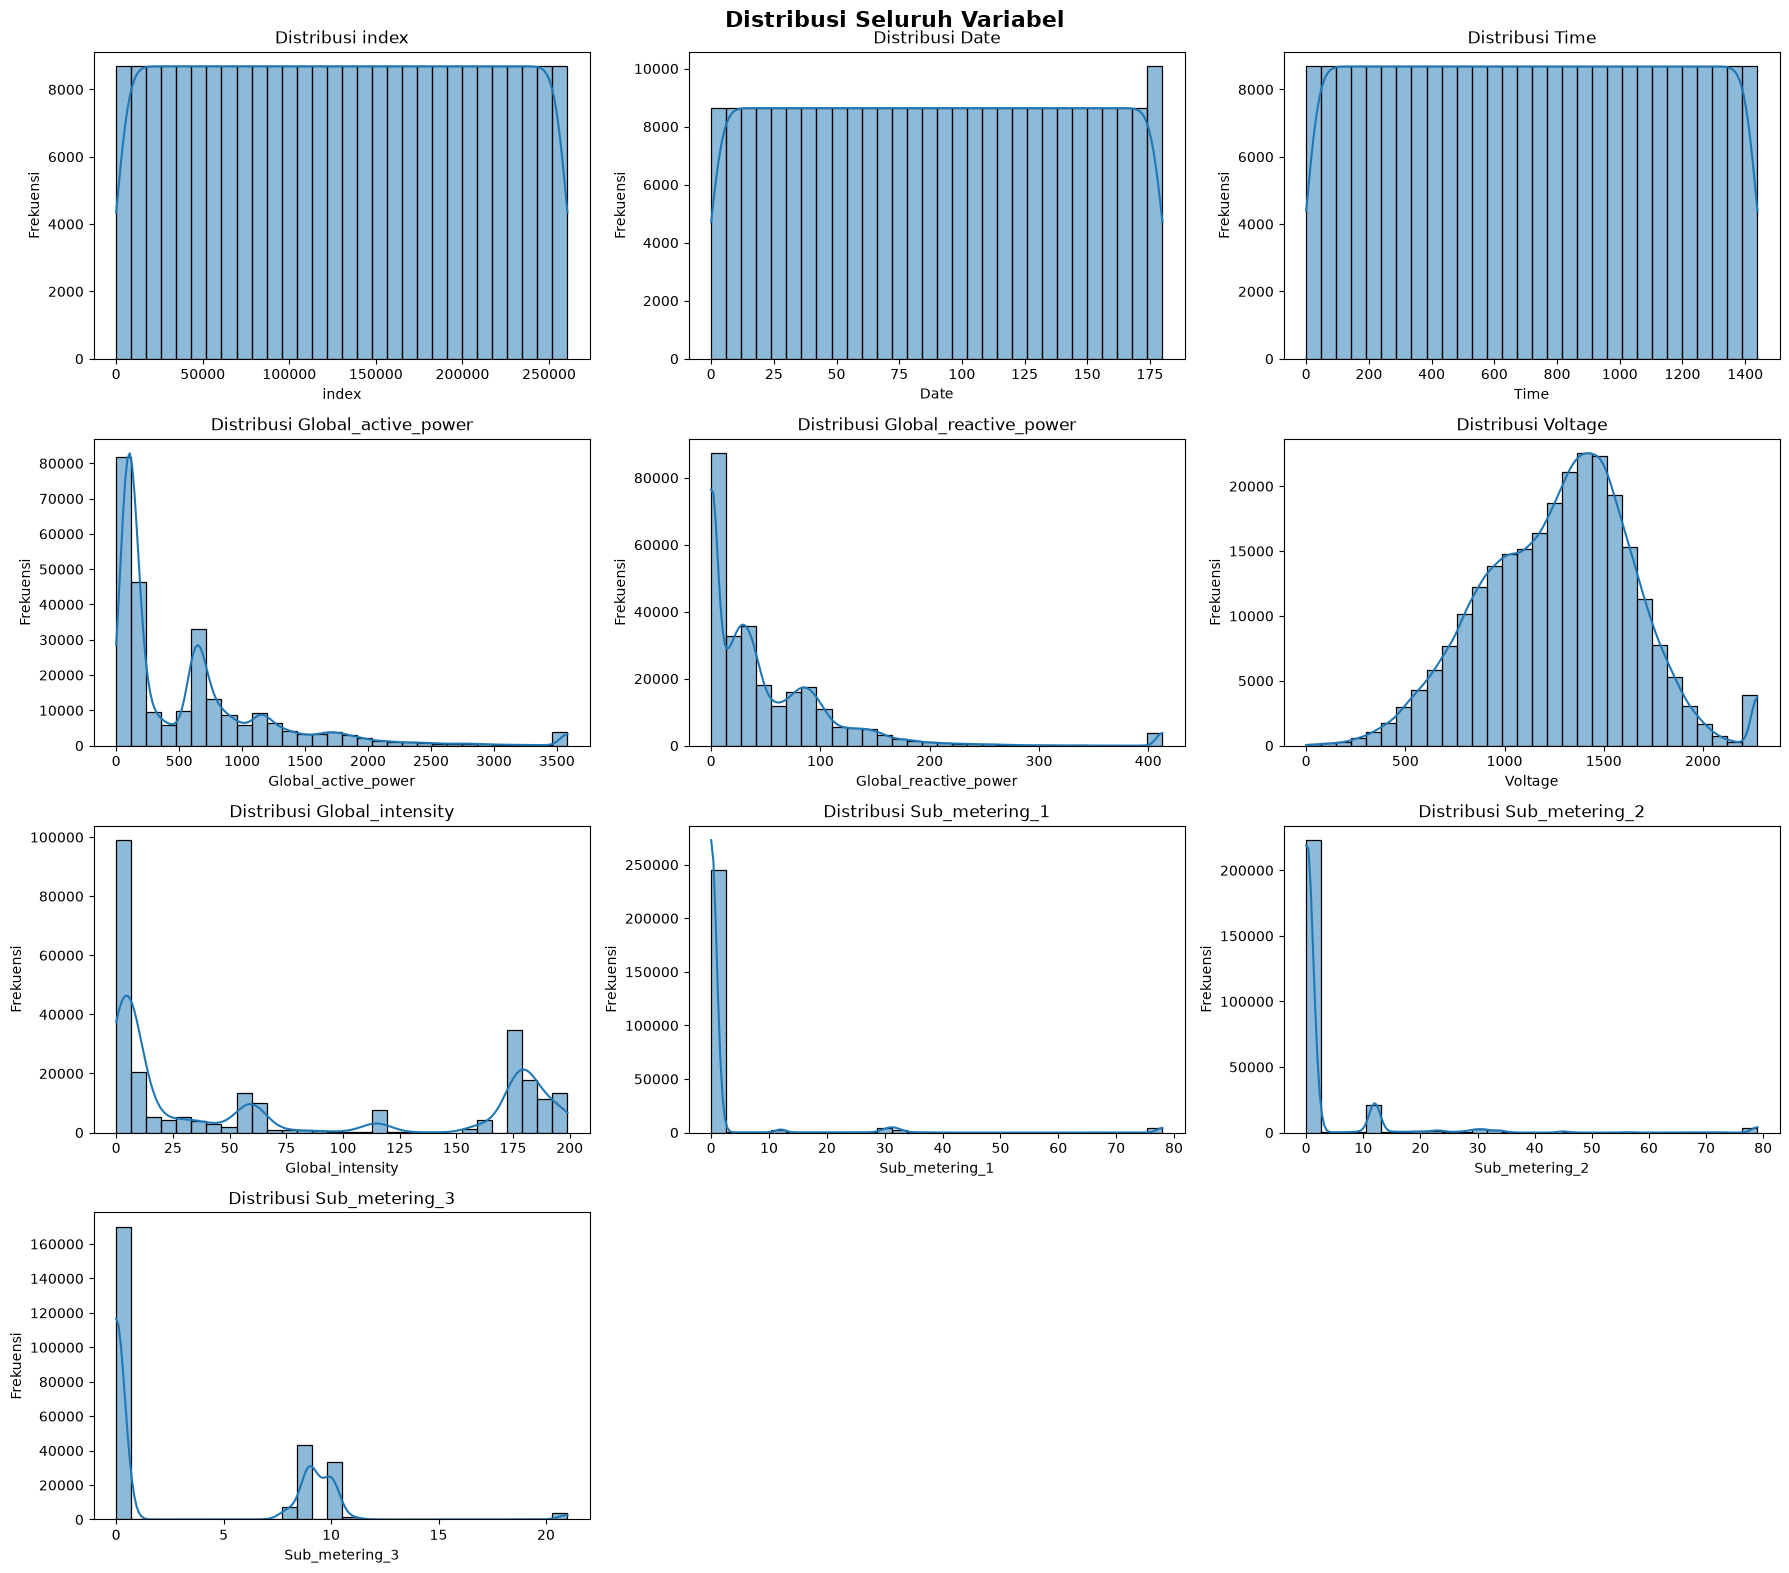

In [10]:
# Mengatur jumlah kolom dan baris subplot
n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

# Membuat subplot
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 4)
)

axes = np.array(axes).flatten()

# Membuat histogram tiap kolom
for i, col in enumerate(numeric_cols):

    sns.histplot(
        data=df_encoded,
        x=col,
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

# Menghapus subplot kosong
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

# Mengatur layout
plt.suptitle(
    'Distribusi Seluruh Variabel',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Bivariat

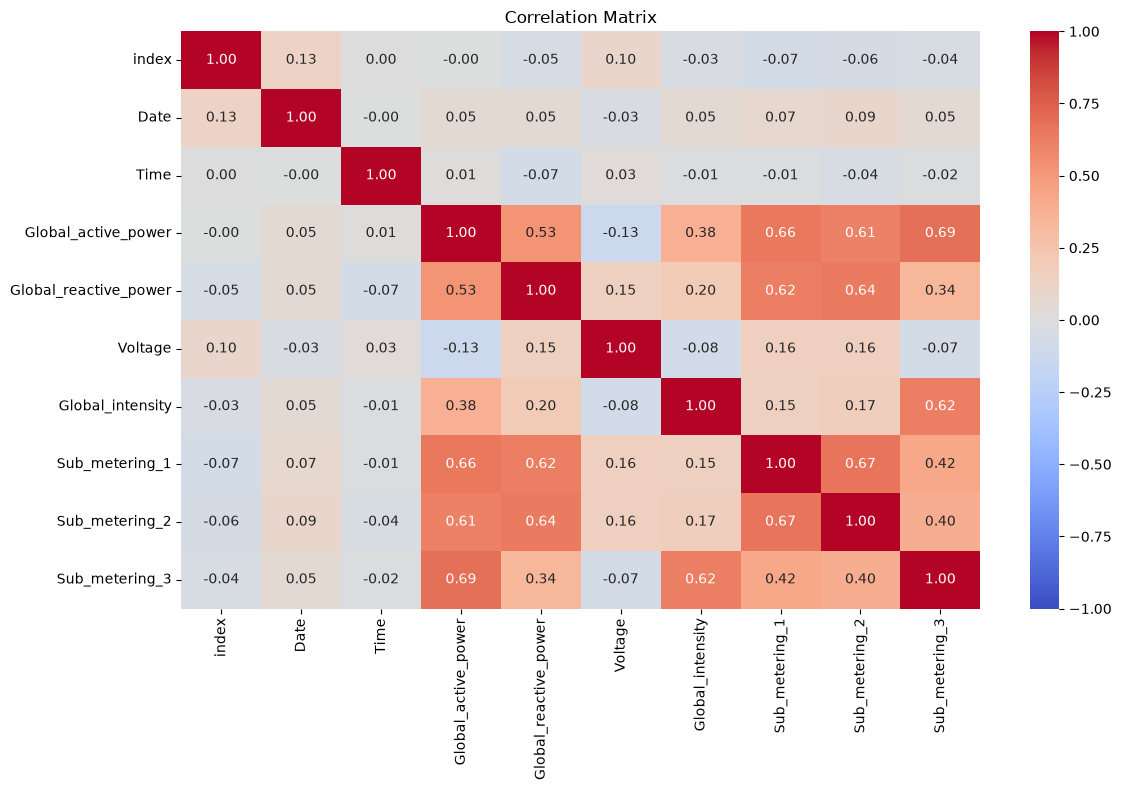

In [11]:
# Menghitung korelasi kolom numerik
corr = df_encoded.corr(numeric_only=True)

# Visualisasi heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# Penanganan

## Feature Engineering

In [12]:
df["datetime"] = pd.to_datetime(
    df["Date"].astype(str).str.strip() + " " +
    df["Time"].astype(str).str.strip(),
    format="mixed",
    dayfirst=True,
    errors="coerce"
)
df.head(5)

,index,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,datetime
0,0,1/1/07,0:00:00,2.58,0.136,241.97,10.6,0,0,0.0,2007-01-01 00:00:00
1,1,1/1/07,0:01:00,2.552,0.1,241.75,10.4,0,0,0.0,2007-01-01 00:01:00
2,2,1/1/07,0:02:00,2.55,0.1,241.64,10.4,0,0,0.0,2007-01-01 00:02:00
3,3,1/1/07,0:03:00,2.55,0.1,241.71,10.4,0,0,0.0,2007-01-01 00:03:00
4,4,1/1/07,0:04:00,2.554,0.1,241.98,10.4,0,0,0.0,2007-01-01 00:04:00


Feature engineering datetime dilakukan dengan menggabungkan kolom Date dan Time dengan tipe data datetime. Hal ini dilakukan untuk menjadi timestamp ketika melakukan forecasting time series

## Tipe Data

In [13]:
cols_to_convert = [
    "Global_active_power", "Global_reactive_power", "Voltage",
    "Global_intensity", "Sub_metering_1", "Sub_metering_2"
]

for col in cols_to_convert:
    df[col] = pd.to_numeric(df[col], errors='coerce')


df.info()

<class 'pandas.DataFrame'>
RangeIndex: 260640 entries, 0 to 260639
Data columns (total 11 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   index                  260640 non-null  int64         
 1   Date                   260640 non-null  str           
 2   Time                   260640 non-null  str           
 3   Global_active_power    256869 non-null  float64       
 4   Global_reactive_power  256869 non-null  float64       
 5   Voltage                256869 non-null  float64       
 6   Global_intensity       256869 non-null  float64       
 7   Sub_metering_1         256869 non-null  float64       
 8   Sub_metering_2         256869 non-null  float64       
 9   Sub_metering_3         256869 non-null  float64       
 10  datetime               260640 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(7), int64(1), str(2)
memory usage: 25.7 MB


Berdasarkan hasil konversi, ditemukan bahwa ketujuh kolom pengukuran masing-masing hanya memiliki 256.869 data yang valid dari total 260.640 baris. Artinya, terdapat 3.771 nilai yang tidak valid atau kosong pada setiap kolom pengukuran.

## Statistik Deskriptif

In [14]:
df.describe()

,index,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,datetime
count,260640.000000,256869.000000,256869.000000,256869.000000,256869.000000,256869.000000,256869.000000,256869.000000,260640
mean,130319.500000,1.164937,0.123729,239.208981,4.974755,1.332481,1.670610,5.831825,2007-04-01 11:59:30
min,0.000000,0.082000,0.000000,223.490000,0.400000,0.000000,0.000000,0.000000,2007-01-01 00:00:00
25%,65159.750000,0.296000,0.000000,236.650000,1.400000,0.000000,0.000000,0.000000,2007-02-15 05:59:45
50%,130319.500000,0.564000,0.104000,239.610000,2.600000,0.000000,0.000000,0.000000,2007-04-01 11:59:30
75%,195479.250000,1.606000,0.194000,241.810000,6.800000,0.000000,1.000000,17.000000,2007-05-16 17:59:15
max,260639.000000,10.670000,1.148000,250.890000,46.400000,78.000000,78.000000,20.000000,2007-06-30 23:59:00
std,75240.431418,1.181832,0.111872,3.592793,4.999493,6.704970,6.631361,8.186709,NaN


Pada kolom Voltage, tegangan listrik tercatat berada pada rentang 223,49–250,89 Volt, dengan rata-rata sebesar 239,21 Volt. Rentang tersebut masih berada dalam batas toleransi umum tegangan listrik rumah tangga, yaitu ±10% dari tegangan nominal 230 Volt. Hal ini menunjukkan bahwa tegangan listrik masih berada dalam rentang yang wajar selama periode pengamatan.

Sementara itu, pada kolom Global_intensity, ditemukan nilai arus maksimum sebesar 46,4 Ampere, jauh lebih tinggi dibandingkan rata-ratanya yang hanya sebesar 4,97 Ampere. Kondisi ini menunjukkan adanya lonjakan penggunaan arus listrik pada waktu tertentu. Temuan tersebut perlu dianalisis lebih lanjut dengan melihat waktu terjadinya lonjakan dan membandingkannya dengan nilai Global_active_power serta ketiga variabel Sub_metering. Analisis ini bertujuan untuk mengetahui apakah lonjakan arus terjadi bersamaan dengan peningkatan penggunaan energi pada salah satu kelompok peralatan listrik atau kombinasi beberapa kelompok peralatan.

Untuk memberikan gambaran, arus listrik sebesar 46,4 Ampere setara dengan arus yang digunakan oleh 13 unit AC 1 PK yang beroperasi bersamaan.

## Missing Value Setiap Kolom

In [15]:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing (%)': round(df.isnull().mean() * 100,2)
})

missing.sort_values(
    by="Missing Count",
    ascending=False
)

,Missing Count,Missing (%)
Voltage,3771,1.45
Global_reactive_power,3771,1.45
Global_active_power,3771,1.45
Sub_metering_1,3771,1.45
Sub_metering_2,3771,1.45
Sub_metering_3,3771,1.45
Global_intensity,3771,1.45
Time,0,0.00
Date,0,0.00
index,0,0.00


Terdapat missing value disemua kolom numerik sebesar 1.45%. Untuk penanganannya perlu dilihat pola missingnya berdasarkan posisi baris dan juga waktu

## Apakah missing value terjadi pada baris yang sama?

In [16]:
numeric_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Memeriksa missing value
missing_mask = df[numeric_cols].isna()

# Seluruh kolom pengukuran missing
all_missing = missing_mask.all(axis=1)

# Minimal satu kolom pengukuran missing
any_missing = missing_mask.any(axis=1)

# Hanya sebagian kolom pengukuran missing
partial_missing = any_missing & ~all_missing

print("Seluruh kolom missing:", all_missing.sum())
print("Sebagian kolom missing:", partial_missing.sum())

# Memeriksa apakah posisi missing identik
same_missing = missing_mask.eq(
    missing_mask.iloc[:, 0],
    axis=0
).all().all()

print("Posisi missing value sama:", same_missing)

Seluruh kolom missing: 3771
Sebagian kolom missing: 0
Posisi missing value sama: True


Setelah dilakukan pemeriksaan posisi missing value, ditemukan bahwa seluruh missing value pada ketujuh kolom berada pada baris yang sama.

## Pola missing value

In [17]:
# Pastikan datetime merupakan kolom
temp = df.copy()

if "datetime" not in temp.columns:
    temp = temp.reset_index()

# Urutkan berdasarkan waktu
temp = temp.sort_values("datetime").copy()

# Identifikasi missing value
missing = temp["Global_active_power"].isna()

# Buat kelompok missing berurutan
groups = missing.ne(missing.shift()).cumsum()

# Buat laporan periode missing
missing_report = (
    temp.loc[missing]
    .groupby(groups[missing])
    .agg(
        start=("datetime", "min"),
        end=("datetime", "max"),
        duration_minutes=("datetime", "size")
    )
    .sort_values(
        "duration_minutes",
        ascending=False
    )
)

display(missing_report)

,start,end,duration_minutes
Global_active_power,,,
10,2007-04-28 00:21:00,2007-04-30 14:23:00,3723
22,2007-06-09 17:59:00,2007-06-09 18:31:00,33
20,2007-06-09 17:55:00,2007-06-09 17:57:00,3
6,2007-02-22 22:58:00,2007-02-22 22:59:00,2
24,2007-06-19 12:14:00,2007-06-19 12:15:00,2
8,2007-03-25 17:52:00,2007-03-25 17:52:00,1
4,2007-01-28 17:13:00,2007-01-28 17:13:00,1
2,2007-01-14 18:36:00,2007-01-14 18:36:00,1
12,2007-06-01 19:14:00,2007-06-01 19:14:00,1


Setelah dilihat berdasarkan waktu terjadinya, mayoritas missing value terkonsentrasi pada periode yang sama, yaitu 28 April 2007 pukul 00:21 hingga 30 April 2007 pukul 14:23, dengan total 3.723 data yang hilang secara berurutan atau sekitar 62 jam 3 menit.

Temuan ini menunjukkan bahwa missing value tidak tersebar secara merata sepanjang periode pengamatan, melainkan didominasi oleh satu gap yang cukup panjang. Kondisi tersebut dapat mengindikasikan adanya gangguan pada proses pencatatan atau pengukuran listrik, meskipun penyebab pastinya belum dapat dipastikan.

Hal seperti ini pernah terjadi di Indonesia pada Mei 2008. Dimana seorang pelanggan melaporkan bahwa meter listrik di rumahnya berhenti bekerja dan kemudian diganti oleh petugas PLN. (https://news.detik.com/suara-pembaca/d-945583/pln-tuduh-konsumen-merusak-segel?)

Oleh karena itu, missing value akan dipertahankan sebagai NaN untuk sementara, kemudian penanganannya akan disesuaikan dengan kebutuhan analisis dan metode forecasting yang digunakan.

## Duplikat Row

In [18]:
# Check duplicate rows
print("Total Duplicate Rows:", df.duplicated().sum())
print("Duplicate Percentage:",
      round(df.duplicated().mean() * 100, 2), "%")

Total Duplicate Rows: 0
Duplicate Percentage: 0.0 %


Tetap tidak terdapat baris yang duplikat setelah penanganan tipe data dan feature engineering

## Outlier

In [19]:
# Memilih kolom numerik
numeric = df.select_dtypes(include='number')

 
# Menghitung kuartil
Q1 = numeric.quantile(0.25)
Q3 = numeric.quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Mendeteksi outlier
outlier = (numeric < lower) | (numeric > upper)

# Membuat tabel ringkasan
outlier_summary = pd.DataFrame({
    'Total Outlier': outlier.sum(),
    'Persentase (%)': (outlier.mean() * 100).round(2)
})

outlier_summary.sort_values(
    by="Total Outlier",
    ascending=False
)

,Total Outlier,Persentase (%)
Sub_metering_1,23199,8.90
Global_intensity,14666,5.63
Global_active_power,13664,5.24
Sub_metering_2,13424,5.15
Global_reactive_power,2210,0.85
Voltage,570,0.22
index,0,0.00
Sub_metering_3,0,0.00


Berdasarkan hasil pemeriksaan outlier, ditemukan bahwa jumlah outlier pada setiap variabel. Tingginya jumlah outlier pada beberapa variabel dapat mengindikasikan adanya variasi penggunaan listrik yang cukup besar. Hal ini dikarenakan konsumsi listrik rumah tangga tidak selalu konstan, melainkan berubah mengikuti aktivitas dan penggunaan peralatan elektronik.

Oleh karena itu, outlier tidak akan langsung dihapus. Pemeriksaan lebih lanjut perlu dilakukan terhadap distribusi data untuk memastikan apakah nilai tersebut merupakan anomali pengukuran atau bagian dari pola konsumsi listrik yang valid.

## Normalitas

In [20]:
# Memilih kolom numerik
numeric_cols = df.select_dtypes(
    include='number'
).columns

results = []

for col in numeric_cols:

    # Konversi menjadi numerik dan hilangkan missing value
    data = pd.to_numeric(
        df_encoded[col], errors='coerce'
    ).dropna()

    if len(data) < 8 or data.nunique() < 2:
        results.append({
            'Kolom': col,
            'P-Value': None,
            'Kesimpulan': 'Tidak dapat diuji'
        })
        continue

    # Uji normalitas
    stat, p_value = normaltest(data)

    results.append({
        'Kolom': col,
        'P-Value': round(p_value,4),
        'Kesimpulan': (
            'Normal (tidak ditolak)'
            if p_value > 0.05
            else 'Tidak Normal'
        )
    })

# Membuat dataframe hasil
normality_summary = pd.DataFrame(results)

normality_summary

,Kolom,P-Value,Kesimpulan
0,index,0.0,Tidak Normal
1,Global_active_power,0.0,Tidak Normal
2,Global_reactive_power,0.0,Tidak Normal
3,Voltage,0.0,Tidak Normal
4,Global_intensity,0.0,Tidak Normal
5,Sub_metering_1,0.0,Tidak Normal
6,Sub_metering_2,0.0,Tidak Normal
7,Sub_metering_3,0.0,Tidak Normal


Berdasarkan hasil uji normalitas, ditemukan bahwa seluruh variabel numerik pengukuran listrik tidak mengikuti distribusi normal.

Namun, kondisi ini bukan berarti terdapat kesalahan pada data. Hal tersebut masih masuk akal karena penggunaan listrik rumah tangga tidak selalu sama sepanjang waktu.

Sebagai contoh, pada pagi dan malam hari penggunaan listrik akan lebih tinggi karena penghuni rumah menggunakan berbagai peralatan elektronik. Sementara itu, pada waktu tertentu penggunaan listrik dapat menurun ketika aktivitas rumah tangga berkurang.

Perbedaan aktivitas tersebut menyebabkan sebagian besar data terkumpul pada tingkat konsumsi tertentu, sedangkan konsumsi yang sangat tinggi hanya terjadi sesekali. Akibatnya, distribusi data tidak selalu membentuk pola normal.

Dengan demikian, distribusi yang tidak normal dapat mencerminkan pola penggunaan listrik rumah tangga yang sebenarnya, bukan semata-mata menunjukkan adanya kesalahan pengukuran.

## Distribusi

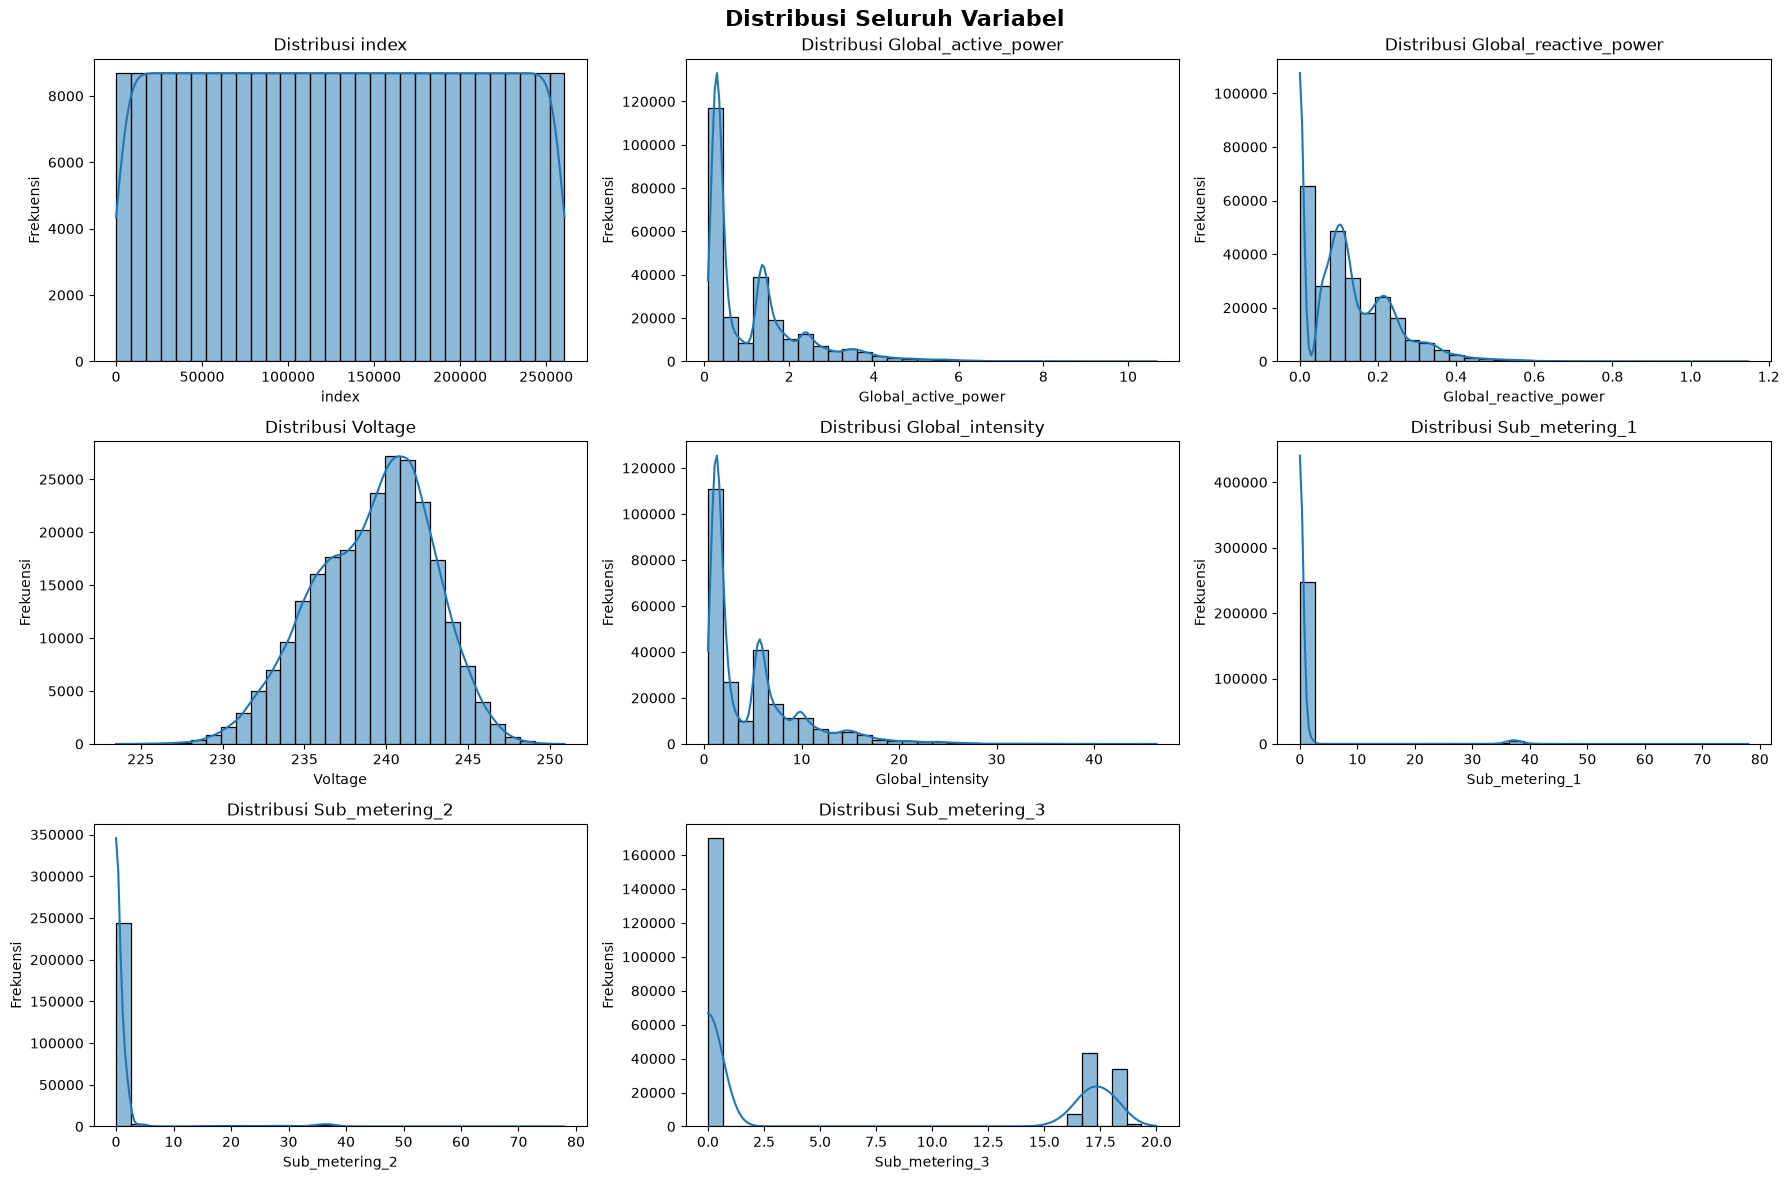

In [21]:
# Mengatur jumlah kolom dan baris subplot
n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

# Membuat subplot
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 4)
)

axes = np.array(axes).flatten()

# Membuat histogram tiap kolom
for i, col in enumerate(numeric_cols):

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

# Menghapus subplot kosong
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

# Mengatur layout
plt.suptitle(
    'Distribusi Seluruh Variabel',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

Berdasarkan hasil visualisasi histogram, ditemukan bahwa sebagian besar variabel pengukuran listrik memiliki distribusi yang tidak simetris dan cenderung miring ke kanan (right-skewed). Hal ini menunjukkan bahwa sebagian besar pengamatan berada pada nilai yang relatif rendah, sementara nilai yang tinggi lebih jarang terjadi.

Pada variabel Global_active_power dan Global_intensity, terlihat bahwa sebagian besar pengamatan terkonsentrasi pada nilai rendah, kemudian frekuensinya semakin menurun seiring meningkatnya daya dan arus listrik. Kondisi ini menunjukkan bahwa penggunaan listrik rumah tangga lebih sering berada pada tingkat rendah hingga sedang, sedangkan penggunaan listrik yang tinggi terjadi lebih jarang.

Berbeda dengan variabel lainnya, Voltage memiliki bentuk distribusi yang relatif menyerupai kurva normal, dengan sebagian besar pengamatan terkonsentrasi di sekitar 239–241 Volt. Hal ini menunjukkan bahwa tegangan listrik cenderung stabil dan hanya mengalami perubahan dalam rentang tertentu.

Tegangan listrik perlu dijaga agar relatif stabil karena setiap peralatan elektronik dirancang untuk bekerja pada rentang tegangan tertentu. Apabila tegangan terlalu rendah atau terlalu tinggi, kinerja peralatan dapat terganggu dan berpotensi menyebabkan kerusakan. Kondisi ini dapat diibaratkan seperti tekanan air yang mengalir melalui pipa rumah. Jika tekanan air terlalu rendah, aliran air menjadi lemah sehingga aktivitas seperti mandi atau mencuci dapat terganggu. Sebaliknya, jika tekanan air terlalu tinggi, tekanan yang berlebihan dapat meningkatkan risiko kerusakan pada pipa atau sambungannya.

## Heatmap Korelasi

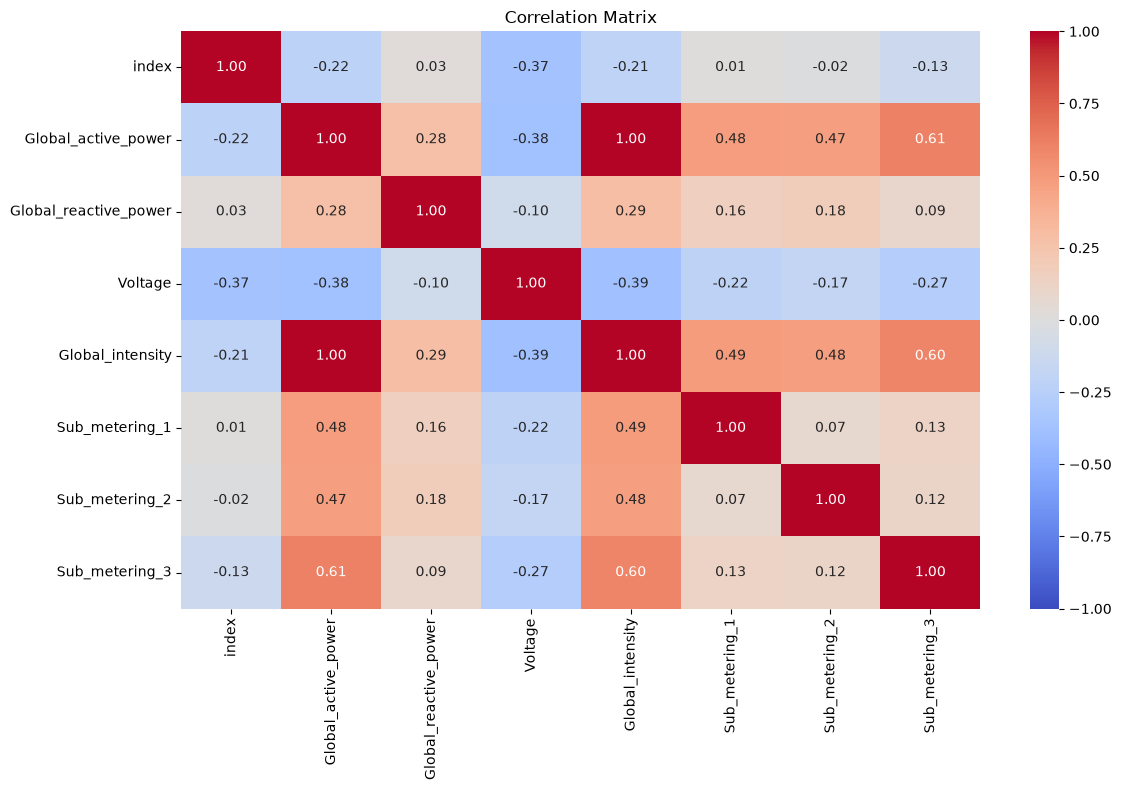

In [22]:
# Menghitung korelasi kolom numerik
corr = df.corr(numeric_only=True)

# Visualisasi heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [23]:
corr = df[
    ["Global_active_power", "Global_intensity"]
].corr()

print("Korelasi Global_active_power dengan Global_intensity:",corr.iloc[0, 1])

Korelasi Global_active_power dengan Global_intensity: 0.9989843455770047


Berdasarkan hasil analisis korelasi, ditemukan bahwa Global_intensity dan Global_active_power memiliki hubungan positif yang sangat kuat, dengan nilai korelasi mendekati 1,00.

Hubungan tersebut dapat dijelaskan menggunakan rumus daya listrik sederhana, yaitu:

P = V × I

Keterangan:

P = Daya listrik (Global_active_power)

V = Tegangan listrik (Voltage)

I = Arus listrik (Global_intensity)

Berdasarkan rumus tersebut, daya listrik berbanding lurus dengan arus apabila tegangan tetap. Dalam dataset ini, tegangan listrik cenderung stabil dengan rata-rata sebesar 239,21 Volt.

Kemudian pada Sub_metering_3 memiliki hubungan positif paling kuat terhadap Global_active_power, yaitu sebesar 0,61, dibandingkan Sub_metering_1 sebesar 0,48 dan Sub_metering_2 sebesar 0,47. Temuan ini menunjukkan bahwa perubahan konsumsi energi pada Sub_metering_3 cenderung memiliki hubungan linear yang lebih kuat dengan perubahan daya aktif total rumah tangga. Namun, korelasi yang lebih tinggi bukan berarti peralatan pada Sub_metering_3 lebih sering digunakan atau menghabiskan listrik lebih banyak. Untuk memastikannya, perlu dilakukan analisis lebih lanjut dengan melihat seberapa sering masing-masing sub-metering mencatat penggunaan listrik dan berapa total energi yang digunakan.

# Analisis

## Penyebab Arus melonjak

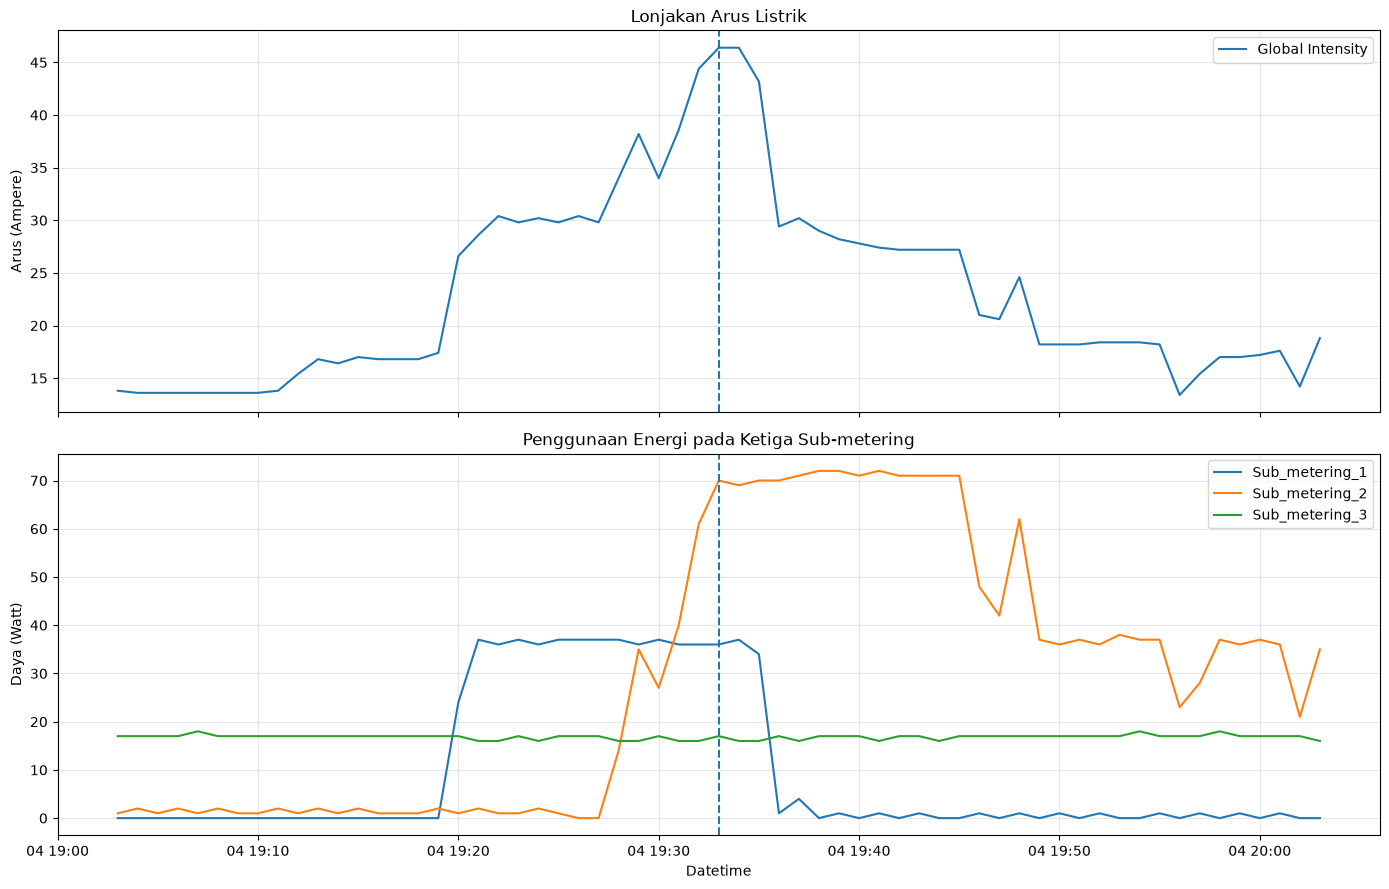

In [51]:
# Menyiapkan data
data = df.copy()

if "datetime" in data.columns:
    data = data.set_index("datetime")

data = data.sort_index()

# Mencari waktu arus maksimum
peak_time = data["Global_intensity"].idxmax()

# Mengambil data 30 menit sebelum dan sesudah puncak
window = data.loc[
    peak_time - pd.Timedelta(minutes=30):
    peak_time + pd.Timedelta(minutes=30)
]

# Membuat dua grafik
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Grafik pertama: Arus listrik
axes[0].plot(
    window.index,
    window["Global_intensity"],
    label="Global Intensity"
)

axes[0].axvline(peak_time, linestyle="--")
axes[0].set_title("Lonjakan Arus Listrik")
axes[0].set_ylabel("Arus (Ampere)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Grafik kedua: Ketiga sub-metering
sub_cols = [
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in sub_cols:
    axes[1].plot(
        window.index,
        window[col],
        label=col
    )

axes[1].axvline(peak_time, linestyle="--")
axes[1].set_title("Penggunaan Energi pada Ketiga Sub-metering")
axes[1].set_ylabel("Daya (Watt)")
axes[1].set_xlabel("Datetime")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
# Menampilkan 10 nilai arus tertinggi
top_current = data.nlargest(
    10,
    "Global_intensity"
)[[
    "Global_intensity",
    "Global_active_power",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]]

top_current.sort_values(
    by="Global_intensity",
    ascending=False
)

,Global_intensity,Global_active_power,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,
2007-03-04 19:33:00,46.4,10.650,36.0,70.0,17.0
2007-03-04 19:34:00,46.4,10.670,37.0,69.0,16.0
2007-03-04 19:32:00,44.4,10.154,36.0,61.0,16.0
2007-03-04 19:35:00,43.2,9.922,34.0,70.0,16.0
2007-02-22 21:14:00,41.8,9.338,33.0,66.0,15.0
2007-02-22 21:15:00,41.8,9.410,34.0,66.0,16.0
2007-02-22 21:08:00,41.4,9.374,35.0,68.0,15.0
2007-02-22 21:09:00,41.4,9.392,34.0,67.0,16.0
2007-02-22 21:10:00,41.2,9.244,34.0,66.0,16.0


Berdasarkan hasil visualisasi, ditemukan bahwa arus listrik mencapai nilai maksimum sebesar 46,4 Ampere pada 4 Maret 2007 pukul 19:33.

Temuan tersebut mengindikasikan bahwa lonjakan arus berkaitan dengan penggunaan beberapa kelompok peralatan listrik secara bersamaan.

Kondisi ini perlu diperhatikan karena semakin besar arus yang mengalir, semakin besar pula beban yang harus ditanggung instalasi listrik. Jika arus melebihi kemampuan kabel atau sistem proteksi, kondisi tersebut dapat meningkatkan risiko panas berlebihan dan gangguan kelistrikan.

Temuan tersebut juga didukung oleh tabel 10 pengamatan arus tertinggi, yang menunjukkan bahwa pola penggunaan listrik cenderung serupa pada saat arus mencapai nilai yang tinggi.

Berdasarkan temuan tersebut, direkomendasikan untuk memastikan kapasitas sambungan listrik dan MCB (Miniature Circuit Breaker) sesuai dengan kebutuhan beban maksimum rumah tangga.

Hal ini bertujuan untuk memastikan bahwa instalasi listrik mampu menanggung arus yang digunakan dan memiliki sistem pengaman yang sesuai. Pemeriksaan juga perlu memperhatikan kemampuan kabel, karena kapasitas MCB tidak boleh melebihi kemampuan penghantar yang dilindunginya.

Hal ini dapat diibaratkan seperti air yang mengalir melalui pipa. Kapasitas sambungan listrik dapat dianalogikan sebagai kemampuan sistem penyediaan air untuk melayani kebutuhan rumah. Sementara itu, kabel listrik dapat diibaratkan sebagai pipa yang memiliki batas kemampuan dalam menyalurkan aliran.

Ketika banyak keran dibuka secara bersamaan, jumlah air yang dibutuhkan akan meningkat. Begitu juga dengan listrik, ketika beberapa peralatan elektronik digunakan bersamaan, arus listrik yang mengalir dapat meningkat.

MCB dapat dianalogikan sebagai katup pengaman otomatis yang memutus aliran ketika arus listrik melampaui batas tertentu, sehingga membantu melindungi kabel dan instalasi dari risiko kerusakan.

## Interpolasi Gap Pendek

In [26]:
df_interp = df.copy()
if "datetime" in df_interp.columns:
    df_interp = df_interp.set_index("datetime")

df_interp = df_interp.sort_index().asfreq("min")

measurement_cols = [
    "Global_active_power", "Global_reactive_power", "Voltage",
    "Global_intensity", "Sub_metering_1", "Sub_metering_2",
    "Sub_metering_3"
]

df_interp[measurement_cols] = df_interp[measurement_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Pada dataset ini, posisi missing pada ketujuh kolom pengukuran identik.
missing = df_interp["Global_active_power"].isna()
gap_groups = missing.ne(missing.shift(fill_value=False)).cumsum()
gap_length = missing.groupby(gap_groups).transform("sum")

# Hanya kelompok missing dengan panjang 1, 2, atau 3 menit
short_gap = missing & gap_length.between(1, 3)

# Interpolasi waktu menghitung kandidat, tetapi HANYA gap pendek yang diisi
candidates = df_interp[measurement_cols].interpolate(
    method="time", limit_area="inside"
)

df_interp.loc[short_gap, measurement_cols] = candidates.loc[
    short_gap, measurement_cols
]

# Simpan jejak observasi yang diestimasi
df_interp["was_imputed"] = short_gap & df_interp[
    "Global_active_power"
].notna()

print("Missing per kolom sebelum:")
print(df[measurement_cols].isna().sum())
print("\nMissing per kolom setelah:")
print(df_interp[measurement_cols].isna().sum())
print("\nBaris yang diinterpolasi:", int(df_interp["was_imputed"].sum()))
print("Sisa baris missing:", int(df_interp["Global_active_power"].isna().sum()))

Missing per kolom sebelum:
Global_active_power      3771
Global_reactive_power    3771
Voltage                  3771
Global_intensity         3771
Sub_metering_1           3771
Sub_metering_2           3771
Sub_metering_3           3771
dtype: int64

Missing per kolom setelah:
Global_active_power      3756
Global_reactive_power    3756
Voltage                  3756
Global_intensity         3756
Sub_metering_1           3756
Sub_metering_2           3756
Sub_metering_3           3756
dtype: int64

Baris yang diinterpolasi: 15
Sisa baris missing: 3756


Metode interpolasi digunakan untuk memperkirakan nilai yang hilang berdasarkan nilai pengamatan sebelum dan sesudahnya, dengan mempertimbangkan jarak waktu antarobservasi. Pendekatan ini dipilih karena perubahan konsumsi listrik dalam interval yang sangat singkat relatif lebih memungkinkan untuk diestimasi dibandingkan kehilangan data dalam durasi panjang.

Sementara itu, missing values pada gap yang melebihi 3 menit tidak dilakukan interpolasi dan tetap dipertahankan sebagai nilai kosong (NaN). Hal ini bertujuan untuk menghindari pembentukan nilai estimasi yang terlalu spekulatif, terutama karena konsumsi listrik rumah tangga dapat mengalami perubahan mendadak akibat aktivitas penggunaan peralatan elektronik.

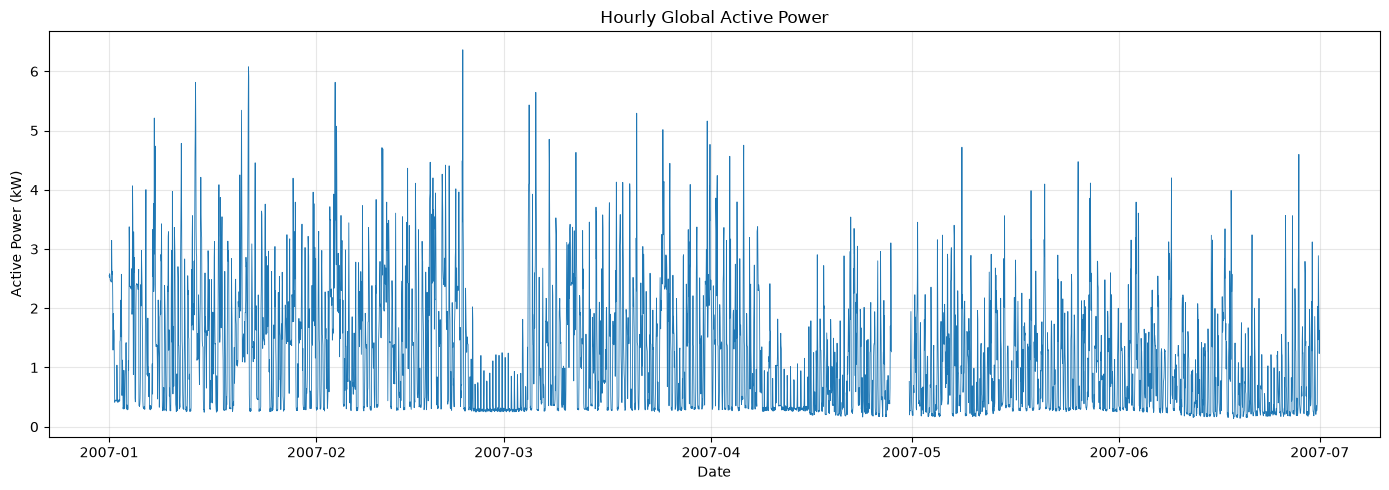

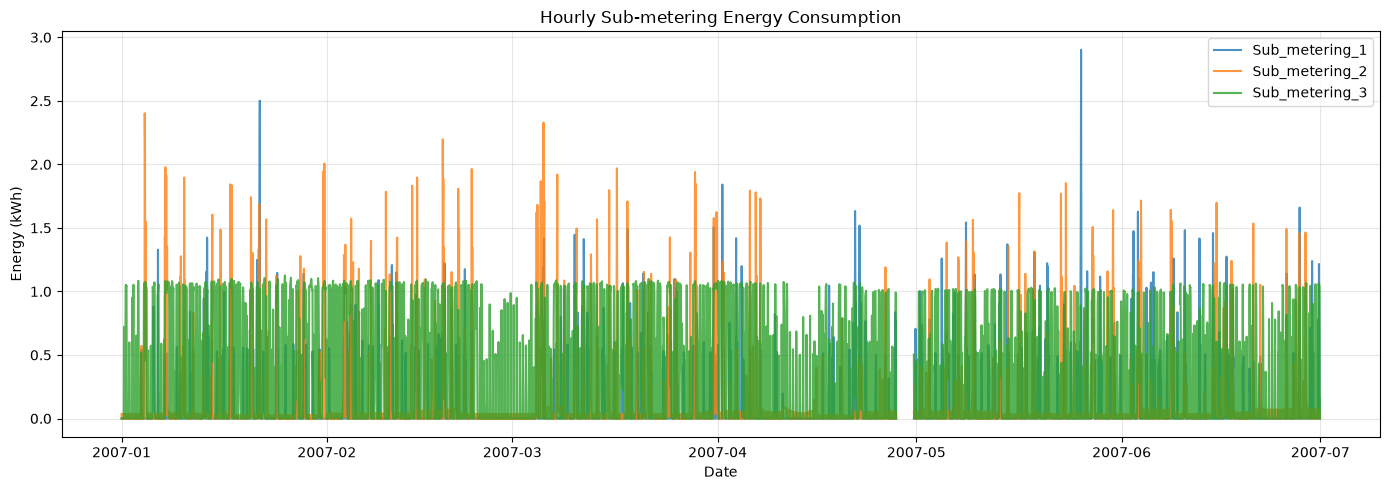

In [27]:
data = df_interp.copy()

if "datetime" in data.columns:
    data = data.set_index("datetime")

data = data.sort_index()

sub_cols = [
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Daya aktif rata-rata per jam (kW)
hourly_power = data["Global_active_power"].resample("h").mean()

# Energi tiap sub-metering per jam (kWh)
hourly_sub = data[sub_cols].resample("h").sum(
    min_count=1
) / 1000

# Hanya pertahankan jam dengan 60 pengukuran valid
power_count = data["Global_active_power"].resample("h").count()
sub_count = data[sub_cols].resample("h").count()

hourly_power = hourly_power.where(power_count == 60)
hourly_sub = hourly_sub.where(sub_count == 60)

# Grafik 1: Tren daya aktif listrik
plt.figure(figsize=(14, 5))

plt.plot(
    hourly_power.index,
    hourly_power,
    linewidth=0.6
)

plt.title("Hourly Global Active Power")
plt.xlabel("Date")
plt.ylabel("Active Power (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Grafik 2: Tren penggunaan sub-metering
plt.figure(figsize=(14, 5))

for col in sub_cols:
    plt.plot(
        hourly_sub.index,
        hourly_sub[col],
        label=col,
        alpha=0.8
    )

plt.title("Hourly Sub-metering Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Setelah proses interpolasi pada gap pendek selesai dilakukan, tahap berikutnya adalah mengubah frekuensi data dari pengamatan per menit menjadi per jam (hourly resampling).

Proses resampling dilakukan terhadap variabel Global_active_power dengan menghitung rata-rata daya aktif pada setiap interval satu jam. Dengan demikian, data yang sebelumnya memiliki frekuensi satu menit diubah menjadi data dengan frekuensi satu jam, sehingga lebih sesuai untuk analisis pola konsumsi listrik dan pembangunan model time series forecasting.

Selain itu, dilakukan agregasi pada variabel Sub_metering_1, Sub_metering_2, dan Sub_metering_3 dengan menjumlahkan energi setiap menit dan mengonversinya menjadi kWh.

Untuk menjaga kualitas data, hanya interval yang memiliki 60 pengamatan menit valid yang dipertahankan. Interval yang belum lengkap tetap diberikan nilai kosong (NaN) agar tidak menghasilkan rata-rata yang kurang representatif akibat missing value.

Hasil resampling kemudian divisualisasikan untuk mengamati perkembangan daya aktif serta penggunaan energi berdasarkan sub-metering sepanjang periode penelitian.

## Moving Average

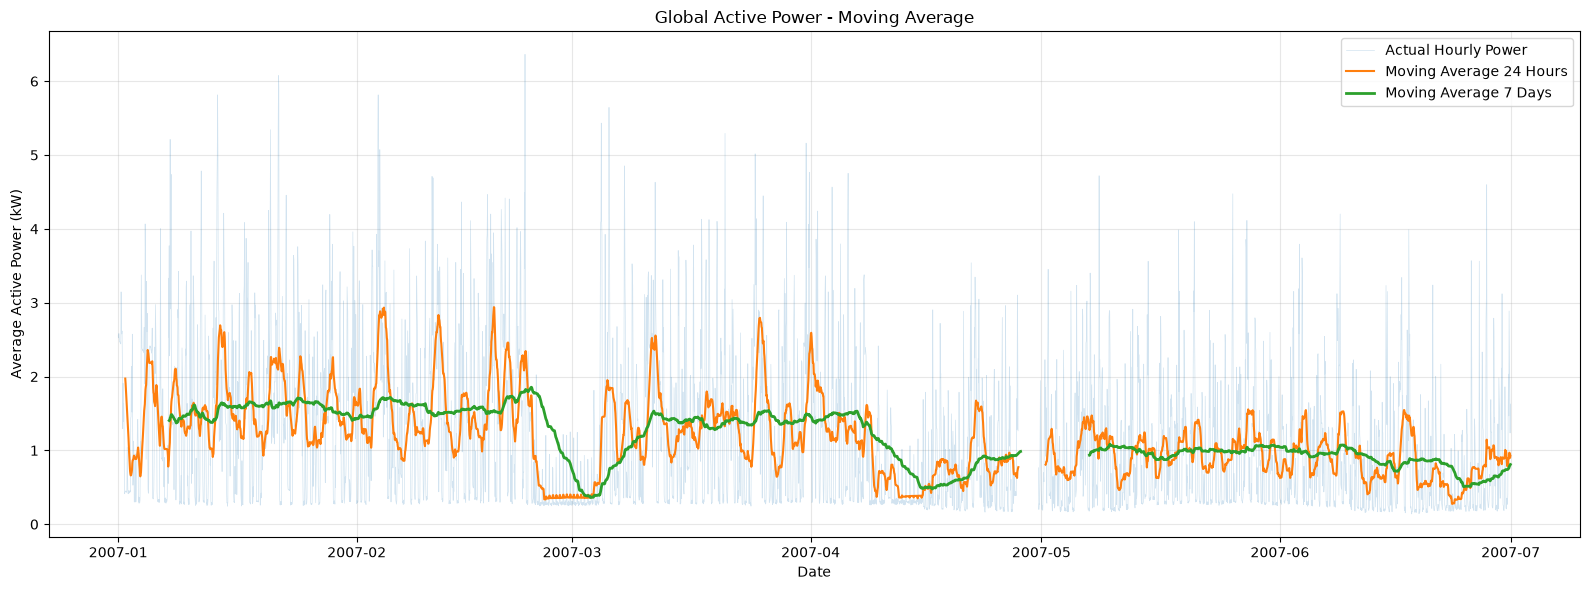

In [28]:
ma_24 = hourly_power.rolling(
    window=24,
    min_periods=23
).mean()

ma_168 = hourly_power.rolling(
    window=168,
    min_periods=160
).mean()

plt.figure(figsize=(16, 6))

plt.plot(
    hourly_power.index,
    hourly_power,
    label="Actual Hourly Power",
    alpha=0.2,
    linewidth=0.5
)

plt.plot(
    ma_24.index,
    ma_24,
    label="Moving Average 24 Hours",
    linewidth=1.5
)

plt.plot(
    ma_168.index,
    ma_168,
    label="Moving Average 7 Days",
    linewidth=2
)

plt.title("Global Active Power - Moving Average")
plt.xlabel("Date")
plt.ylabel("Average Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Setelah data dikonversi menjadi frekuensi per jam, dilakukan analisis Moving Average untuk mengidentifikasi kecenderungan konsumsi listrik dalam jangka waktu tertentu.

Penelitian ini menggunakan dua periode Moving Average, yaitu 24 jam dan 168 jam (7 hari).

Moving Average 24 jam digunakan untuk memperhalus fluktuasi konsumsi dalam jangka pendek, sedangkan Moving Average 168 jam digunakan untuk mengamati kecenderungan perubahan daya listrik dalam periode yang lebih panjang.

Melalui perbandingan data aktual dan kedua Moving Average tersebut, pola umum konsumsi listrik dapat diamati dengan lebih jelas tanpa terlalu dipengaruhi oleh perubahan sesaat.

Analisis Moving Average ini bertujuan untuk memahami karakteristik data sebelum pembangunan model forecasting, bukan untuk mengganti nilai konsumsi aktual atau mengisi missing value yang masih tersisa.

## Split Data

In [29]:
# Menggunakan data asli untuk tahap modeling
data_model = df_interp.copy()

if "datetime" in data_model.columns:
    data_model = data_model.set_index("datetime")

data_model = data_model.sort_index().asfreq("min")

# Menentukan batas split dari seluruh timeline
hours = data_model.resample("h").size().index

val_start = hours[int(len(hours) * 0.64)]
test_start = hours[int(len(hours) * 0.80)]

# Membagi secara kronologis
train = data_model.loc[
    data_model.index < val_start
].copy()

validation = data_model.loc[
    (data_model.index >= val_start) &
    (data_model.index < test_start)
].copy()

test = data_model.loc[
    data_model.index >= test_start
].copy()

# Memeriksa hasil
for name, dataset in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(f"\n{name}")
    print("Jumlah:", len(dataset))
    print("Awal:", dataset.index.min())
    print("Akhir:", dataset.index.max())


Train
Jumlah: 166800
Awal: 2007-01-01 00:00:00
Akhir: 2007-04-26 19:59:00

Validation
Jumlah: 41700
Awal: 2007-04-26 20:00:00
Akhir: 2007-05-25 18:59:00

Test
Jumlah: 52140
Awal: 2007-05-25 19:00:00
Akhir: 2007-06-30 23:59:00


In [30]:
# Fungsi resampling daya aktif menjadi per jam

def resample_hourly(dataset):

    # Rata-rata Global Active Power setiap jam
    hourly = dataset["Global_active_power"].resample("h").mean()

    # Jumlah pengamatan valid dalam setiap jam
    count = dataset["Global_active_power"].resample("h").count()

    # Hanya mempertahankan jam dengan 60 data valid
    hourly = hourly.where(count == 60)

    return hourly


# Resampling masing-masing dataset
train_hourly = resample_hourly(train)

validation_hourly = resample_hourly(validation)

test_hourly = resample_hourly(test)


# Memeriksa hasil
for name, dataset in [
    ("Train", train_hourly),
    ("Validation", validation_hourly),
    ("Test", test_hourly)
]:
    print(f"\n{name}")
    print("Jumlah jam:", len(dataset))
    print("Data valid:", dataset.notna().sum())
    print("Missing:", dataset.isna().sum())


Train
Jumlah jam: 2780
Data valid: 2780
Missing: 0

Validation
Jumlah jam: 695
Data valid: 632
Missing: 63

Test
Jumlah jam: 869
Data valid: 867
Missing: 2


Tahap berikutnya adalah membagi dataset menjadi tiga kelompok, yaitu Training, Validation, dan Testing.

Pembagian dilakukan secara kronologis dengan mempertahankan urutan waktu pengamatan. Metode ini dipilih karena penelitian bertujuan memprediksi konsumsi listrik pada periode berikutnya berdasarkan informasi historis.

Proporsi pembagian data ditetapkan sebesar 64% untuk Training, 16% untuk Validation, dan 20% untuk Testing.

## Uji Stasioner (ADF Test)

In [31]:
result = adfuller(train_hourly)

print("ADF Statistic:", result[0])
print("P-Value:", result[1])

if result[1] < 0.05:
    print("Tolak H0: terdapat bukti mendukung stasioneritas")
else:
    print("Gagal menolak H0: belum cukup bukti stasioneritas")

ADF Statistic: -6.611277255440706
P-Value: 6.36785095944499e-09
Tolak H0: terdapat bukti mendukung stasioneritas


Sebelum pembangunan model, dilakukan pengujian stasioneritas menggunakan Augmented Dickey-Fuller (ADF) Test pada data Training.

Berdasarkan hasil pengujian, diperoleh nilai ADF Statistic sebesar −6,6113 dan p-value sebesar 6,37 × 10⁻⁹.

Karena nilai p-value lebih kecil dari tingkat signifikansi 0,05, hipotesis nol yang menyatakan data tidak stasioner ditolak.

## Daily Seasonality, ACF, dan PACF

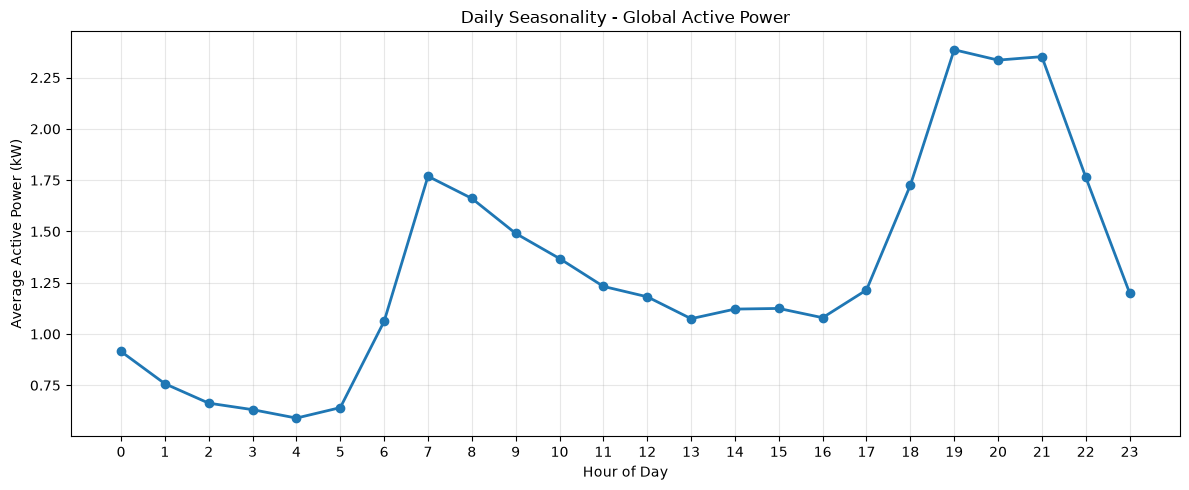

In [32]:
# Rata-rata daya aktif setiap jam
hourly_pattern = train_hourly.groupby(
    train_hourly.index.hour
).mean()

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern.values,
    marker="o",
    linewidth=2
)

plt.title("Daily Seasonality - Global Active Power")
plt.xlabel("Hour of Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Grafik Daily Seasonality digunakan untuk mengidentifikasi rata-rata konsumsi listrik berdasarkan jam dalam sehari. Hasil visualisasi menunjukkan adanya perubahan pola konsumsi antara dini hari, pagi, dan malam.

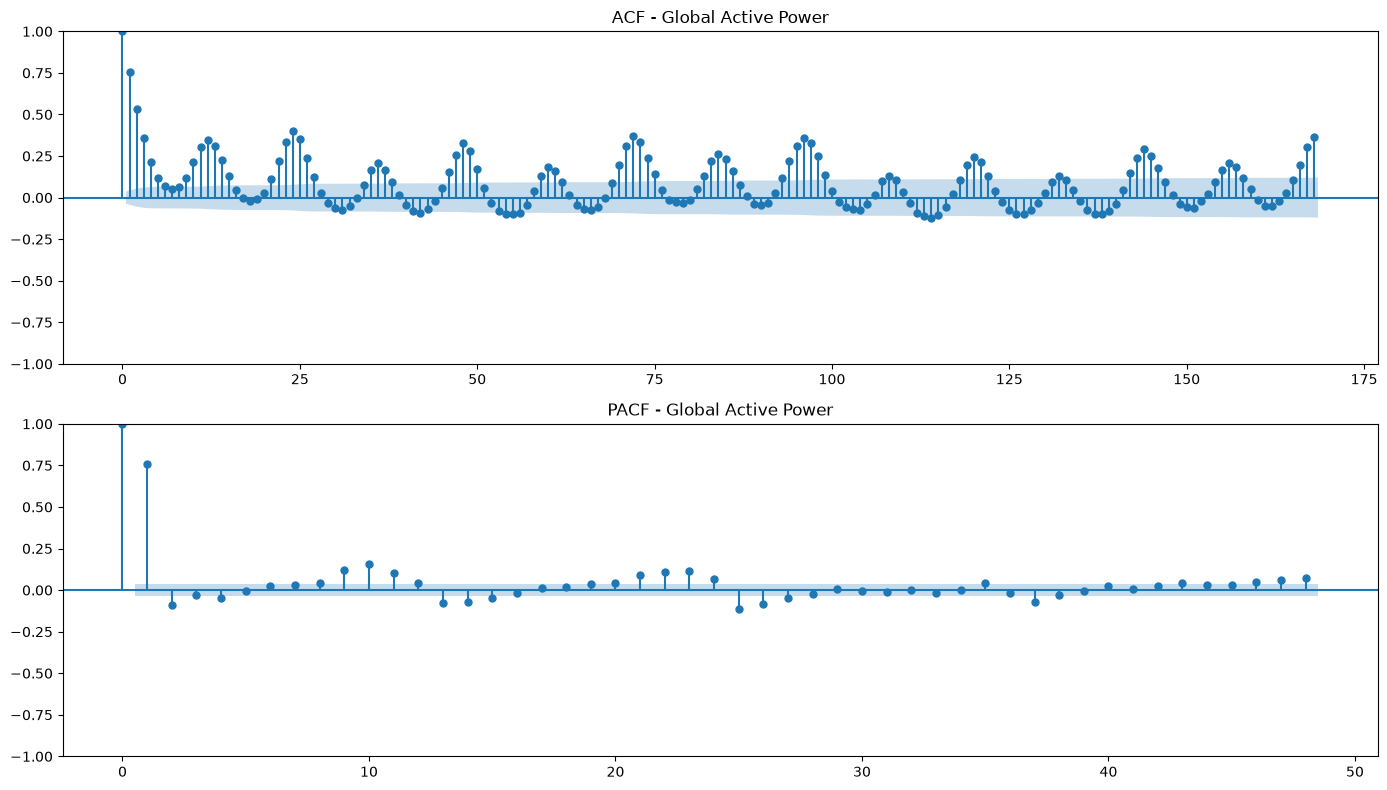

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Autocorrelation
plot_acf(
    train_hourly,
    lags=168,
    ax=axes[0]
)

axes[0].set_title("ACF - Global Active Power")

# Partial Autocorrelation
plot_pacf(
    train_hourly,
    lags=48,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF - Global Active Power")

plt.tight_layout()
plt.show()

Selanjutnya, grafik ACF digunakan untuk mengamati hubungan antara konsumsi listrik saat ini dengan pengamatan pada waktu sebelumnya. Dari pola autokorelasi, terlihat indikasi hubungan yang berulang pada lag 24 jam dan kelipatannya.

Sementara itu, PACF digunakan untuk membantu mengidentifikasi hubungan langsung antara suatu pengamatan dengan lag tertentu setelah memperhitungkan lag lainnya.

Berdasarkan analisis tersebut, periode musiman 24 jam dipilih sebagai kandidat dalam model SARIMA karena data memiliki frekuensi per jam dan menunjukkan indikasi pola konsumsi harian.

## SARIMA

SARIMA terlebih dahulu dilatih memakai data Training, kemudian diuji pada data Validation untuk mengetahui apakah pola yang dipelajari model membantu menghasilkan prediksi yang mendekati kenyataan. Data Testing belum digunakan pada tahap ini.

In [34]:
# Menyiapkan data training
y_train = train_hourly.astype(float)

# Model SARIMA awal
model = SARIMAX(
    y_train,
    order=(1, 0, 0),
    seasonal_order=(1, 0, 0, 24),
    trend="c",
    enforce_stationarity=True,
    enforce_invertibility=True
)

# Melatih model
sarima_result = model.fit(disp=False)

# Ringkasan hasil
print(sarima_result.summary())

print("\nModel Converged:")
print(sarima_result.mle_retvals["converged"])

                                     SARIMAX Results                                      
Dep. Variable:                Global_active_power   No. Observations:                 2780
Model:             SARIMAX(1, 0, 0)x(1, 0, 0, 24)   Log Likelihood               -2904.865
Date:                            Tue, 10 Nov 2026   AIC                           5817.729
Time:                                    18:47:44   BIC                           5841.450
Sample:                                01-01-2007   HQIC                          5826.295
                                     - 04-26-2007                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.2569      0.026      9.894      0.000       0.206       0.308
ar.L1          0.7316      0.012   

In [35]:
# Menggunakan data asli
raw = df.copy()

# Membentuk ulang datetime
raw["datetime"] = pd.to_datetime(
    raw["Date"].astype(str).str.strip() + " " +
    raw["Time"].astype(str).str.strip(),
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Jadikan datetime sebagai index
raw = raw.set_index("datetime").sort_index()


# Mengambil daya aktif asli
power_raw = pd.to_numeric(
    raw["Global_active_power"],
    errors="coerce"
)

# Resampling data asli per jam
val_count = power_raw.resample("h").count()

val_actual = (
    power_raw.resample("h").mean()
    .where(val_count == 60)
    .reindex(validation_hourly.index)
)

# Update model dengan observasi validation
# tanpa melatih ulang parameter
updated_result = sarima_result.append(
    val_actual,
    refit=False
)

# Prediksi satu jam ke depan
val_pred = updated_result.get_prediction(
    start=val_actual.index[0],
    end=val_actual.index[-1],
    dynamic=False
).predicted_mean

# Evaluasi hanya pada jam yang valid
valid_mask = val_actual.notna() & val_pred.notna()

actual = val_actual[valid_mask]
predicted = val_pred[valid_mask]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(np.mean((actual - predicted) ** 2))

print("Hasil Evaluasi SARIMA")
print("Jumlah jam evaluasi:", valid_mask.sum())
print(f"MAE  : {mae:.4f} kW")
print(f"RMSE : {rmse:.4f} kW")

Hasil Evaluasi SARIMA
Jumlah jam evaluasi: 632
MAE  : 0.4583 kW
RMSE : 0.6250 kW


Setelah model dilatih, hasil prediksinya dibandingkan dengan konsumsi listrik yang benar-benar tercatat. Hanya jam yang memiliki 60 pengukuran menit lengkap dari data asli yang digunakan agar nilai aktualnya dapat dipercaya.

Dari 632 jam yang bisa dievaluasi, diperoleh MAE 0,4583 kW dan RMSE 0,6250 kW. Artinya, selisih prediksi SARIMA terhadap data aktual rata-rata sekitar 0,46 kW jika dihitung menggunakan MAE. Semakin kecil nilai MAE dan RMSE, semakin baik.

In [36]:
# Data training dan validation
y_train = train_hourly.astype(float).asfreq("h")
y_val = val_actual.astype(float).asfreq("h")

# Memastikan data training lengkap
assert y_train.notna().all(), "Training masih memiliki NaN"

# Memastikan periode validation tepat setelah training
assert y_val.index.min() == (
    y_train.index.max() + pd.Timedelta(hours=1)
), "Periode training dan validation tidak berurutan"

# Kandidat parameter SARIMA
candidates = {
    "SARIMA 1": ((1, 0, 0), (1, 0, 0, 24)),
    "SARIMA 2": ((1, 0, 1), (1, 0, 0, 24)),
    "SARIMA 3": ((2, 0, 0), (1, 0, 0, 24)),
    "SARIMA 4": ((1, 0, 0), (0, 0, 1, 24))
}

predictions = {}
model_info = []

for name, (order, seasonal_order) in candidates.items():

    print(f"Melatih {name} ...")

    try:
        # Melatih SARIMA hanya pada training
        model = SARIMAX(
            y_train,
            order=order,
            seasonal_order=seasonal_order,
            trend="c",
            enforce_stationarity=True,
            enforce_invertibility=True
        )

        fitted = model.fit(
            disp=False,
            maxiter=100
        )

        converged = fitted.mle_retvals.get(
            "converged", False
        )

        # Memasukkan observasi validation secara
        # berurutan, tanpa melatih ulang parameter
        updated = fitted.append(
            y_val,
            refit=False
        )

        # Prediksi one-step-ahead
        pred = updated.get_prediction(
            start=len(y_train),
            end=len(y_train) + len(y_val) - 1,
            dynamic=False
        ).predicted_mean

        pred.index = y_val.index

        predictions[name] = pred

        model_info.append({
            "Model": name,
            "Order": str(order),
            "Seasonal": str(seasonal_order),
            "AIC": fitted.aic,
            "Converged": converged
        })

    except Exception as e:
        print(f"{name} gagal: {e}")


# Membandingkan hanya timestamp yang sama
comparison = pd.DataFrame({
    "Actual": y_val,
    **predictions
}).dropna()

if comparison.empty:
    raise ValueError("Tidak ada timestamp evaluasi bersama")

results = []

for info in model_info:

    name = info["Model"]

    actual = comparison["Actual"]
    predicted = comparison[name]

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    results.append({
        **info,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)

# Urutkan berdasarkan MAE terkecil
results_df = results_df.sort_values("MAE")

print("Jumlah jam evaluasi:", len(comparison))

display(results_df.round(4))

Melatih SARIMA 1 ...
Melatih SARIMA 2 ...
Melatih SARIMA 3 ...
Melatih SARIMA 4 ...
Jumlah jam evaluasi: 632


,Model,Order,Seasonal,AIC,Converged,MAE,RMSE
0,SARIMA 1,"(1, 0, 0)","(1, 0, 0, 24)",5817.7293,True,0.4583,0.6250
2,SARIMA 3,"(2, 0, 0)","(1, 0, 0, 24)",5816.8694,True,0.4590,0.6261
1,SARIMA 2,"(1, 0, 1)","(1, 0, 0, 24)",5816.8016,True,0.4591,0.6262
3,SARIMA 4,"(1, 0, 0)","(0, 0, 1, 24)",5874.8866,True,0.4613,0.6251


Satu model bisa menghasilkan prediksi berbeda ketika pengaturannya diubah. Karena itu, dilakukan percobaan terhadap empat pengaturan SARIMA dan membandingkan kesalahannya pada Data Validation.

Keempatnya berhasil dilatih. Dari hasil perbandingan, SARIMA 1 dengan pengaturan (1,0,0)(1,0,0,24) memberikan MAE paling kecil, yaitu 0,4583 kW pada 632 jam Validation. Pengaturan inilah yang dipilih untuk digunakan pada tahap selanjutnya.

## Seasonal Naive

In [37]:
# 1. Memilih SARIMA terbaik yang berhasil konvergen
valid_models = results_df[
    results_df["Converged"] == True
]

if valid_models.empty:
    raise ValueError("Tidak ada model SARIMA yang konvergen")

best_model = valid_models.sort_values(
    ["MAE", "RMSE"]
).iloc[0]

best_name = best_model["Model"]

# Prediksi SARIMA terbaik pada validation
sarima_pred = predictions[best_name].reindex(
    val_actual.index
)

# 2. Membuat prediksi Seasonal Naive
# Gabungkan riwayat train dan aktual validation
history = pd.concat([
    train_hourly,
    val_actual
]).sort_index().asfreq("h")

# Prediksi menggunakan 24 jam sebelumnya
naive_pred = history.shift(24).reindex(
    val_actual.index
)

# 3. Menyamakan timestamp evaluasi
comparison = pd.DataFrame({
    "Actual": val_actual,
    "SARIMA": sarima_pred,
    "Seasonal Naive": naive_pred
}).dropna()

if comparison.empty:
    raise ValueError("Tidak ada timestamp evaluasi bersama")

# 4. Menghitung MAE dan RMSE
results = []

for model_name in ["SARIMA", "Seasonal Naive"]:

    error = (
        comparison["Actual"] -
        comparison[model_name]
    )

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

comparison_results = pd.DataFrame(results)

# 5. Menampilkan hasil
print("SARIMA Terbaik:", best_name)
print("Order:", best_model["Order"])
print("Seasonal Order:", best_model["Seasonal"])
print("Jumlah jam evaluasi:", len(comparison))

display(comparison_results.round(4))

SARIMA Terbaik: SARIMA 1
Order: (1, 0, 0)
Seasonal Order: (1, 0, 0, 24)
Jumlah jam evaluasi: 608


,Model,MAE,RMSE
0,SARIMA,0.4593,0.6298
1,Seasonal Naive,0.6189,0.9066


Untuk mengetahui apakah SARIMA benar-benar memberikan hasil yang lebih baik, digunakan juga metode prediksi yang sangat sederhana, yaitu Seasonal Naive.

Hasilnya, SARIMA memiliki MAE 0,4593 kW, sedangkan Seasonal Naive memiliki MAE 0,6189 kW. Dengan kata lain, pada pengujian ini SARIMA lebih mendekati nilai aktual daripada cara sederhana yang hanya menyalin konsumsi pada jam yang sama sehari sebelumnya.

## XGBoost

Setelah SARIMA, tahap berikutnya menggunakan XGBoost, yaitu model machine learning yang belajar dari banyak contoh dan memperbaiki kesalahan prediksi secara bertahap.

Berbeda dari SARIMA, XGBoost perlu diberi beberapa informasi sebagai petunjuk, misalnya pemakaian listrik pada jam-jam sebelumnya dan kapan pengukuran dilakukan. Model kemudian mempelajari hubungan antara petunjuk tersebut dengan konsumsi listrik yang sebenarnya.

In [38]:
# Menggabungkan riwayat training dan validation
# Validation menggunakan data aktual asli
history = pd.concat([
    train_hourly,
    val_actual
]).sort_index().asfreq("h")

# Fungsi membuat fitur time series
def create_features(series):
    data = pd.DataFrame(index=series.index)

    data["target"] = series

    # Fitur lag (hanya dari waktu sebelumnya)
    data["lag_1"] = series.shift(1)
    data["lag_2"] = series.shift(2)
    data["lag_3"] = series.shift(3)
    data["lag_24"] = series.shift(24)

    # Fitur kalender
    data["hour"] = series.index.hour
    data["day_of_week"] = series.index.dayofweek
    data["is_weekend"] = (
        series.index.dayofweek >= 5
    ).astype(int)

    return data

# Membuat fitur
features = create_features(history)

feature_cols = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_24",
    "hour",
    "day_of_week",
    "is_weekend"
]

# Pisahkan berdasarkan periode yang sudah ditentukan
train_features = features.loc[train_hourly.index].copy()
val_features = features.loc[val_actual.index].copy()

# Hapus baris yang tidak mempunyai target atau fitur lengkap
train_features = train_features.dropna(
    subset=["target"] + feature_cols
)

val_features = val_features.dropna(
    subset=["target"] + feature_cols
)

# Menentukan X dan y
X_train = train_features[feature_cols]
y_train_xgb = train_features["target"]

X_val = val_features[feature_cols]
y_val_xgb = val_features["target"]

print("Jumlah training:", len(X_train))
print("Jumlah validation:", len(X_val))

display(X_train.head())

Jumlah training: 2756
Jumlah validation: 608


,lag_1,lag_2,lag_3,lag_24,hour,day_of_week,is_weekend
datetime,,,,,,,
2007-01-02 00:00:00,0.449967,0.443733,0.433933,2.550633,0,1,0
2007-01-02 01:00:00,0.446433,0.449967,0.443733,2.523400,1,1,0
2007-01-02 02:00:00,0.436733,0.446433,0.449967,2.582333,2,1,0
2007-01-02 03:00:00,0.431567,0.436733,0.446433,2.541667,3,1,0
2007-01-02 04:00:00,0.464167,0.431567,0.436733,2.475733,4,1,0


Sebelum melatih XGBoost, dibuat beberapa fitur, yaitu informasi yang dipakai model untuk menebak konsumsi listrik. Fitur tersebut terdiri dari konsumsi 1, 2, 3, dan 24 jam sebelumnya, jam dalam sehari, hari dalam seminggu, serta penanda akhir pekan.

In [39]:
# Membangun model XGBoost awal
xgb_model = XGBRegressor(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=4
)

# Melatih hanya menggunakan training
xgb_model.fit(X_train, y_train_xgb)

# Prediksi validation
xgb_pred = pd.Series(
    xgb_model.predict(X_val),
    index=X_val.index,
    name="XGBoost"
)

print("Model XGBoost berhasil dilatih.")

Model XGBoost berhasil dilatih.


XGBoost terlebih dahulu dilatih dengan satu pengaturan awal: 400 pohon keputusan, kedalaman maksimum 4, dan learning rate 0,05. Pohon keputusan dapat dibayangkan sebagai serangkaian aturan yang membantu model memperkirakan konsumsi listrik.

Model belajar hanya dari Training, lalu mencoba memprediksi data Validation. Hasil model awal ini akan dibandingkan dengan beberapa pengaturan lain untuk melihat apakah prediksinya masih bisa ditingkatkan.

In [40]:
# 1. Membuat fitur XGBoost
def create_features(series):
    data = pd.DataFrame(index=series.index)
    data["target"] = series

    for lag in [1, 2, 3, 24]:
        data[f"lag_{lag}"] = series.shift(lag)

    data["hour"] = series.index.hour
    data["day_of_week"] = series.index.dayofweek
    data["is_weekend"] = (
        series.index.dayofweek >= 5
    ).astype(int)

    return data


# 2. Menyiapkan data historis
# Gunakan nilai aktual validation, bukan prediksi
history_xgb = pd.concat([
    train_hourly,
    val_actual
]).sort_index().asfreq("h")

features_xgb = create_features(history_xgb)

feature_cols = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_24",
    "hour",
    "day_of_week",
    "is_weekend"
]


# 3. Menyiapkan training dan validation
train_features = features_xgb.loc[
    train_hourly.index
].dropna(subset=["target"] + feature_cols)

val_features = features_xgb.loc[
    val_actual.index
].dropna(subset=["target"] + feature_cols)

X_train = train_features[feature_cols].copy()
y_train_xgb = train_features["target"].copy()

X_val = val_features[feature_cols].copy()
y_val_xgb = val_features["target"].copy()


# 4. Data evaluasi validation
# Tidak memakai comparison_all atau eval_index
X_eval = X_val.copy()
y_eval = y_val_xgb.copy()

# Pemeriksaan sebelum tuning
assert isinstance(X_eval, pd.DataFrame)
assert isinstance(y_eval, pd.Series)
assert X_eval.index.equals(y_eval.index)
assert len(X_train) > 0
assert len(X_eval) > 0

print("Data training   :", len(X_train))
print("Data validation :", len(X_eval))
print("Index sesuai    :", X_eval.index.equals(y_eval.index))


# 5. Kandidat hyperparameter XGBoost
candidates = {
    "XGBoost Awal": {
        "n_estimators": 400,
        "max_depth": 4,
        "learning_rate": 0.05
    },
    "XGBoost 2": {
        "n_estimators": 300,
        "max_depth": 3,
        "learning_rate": 0.05
    },
    "XGBoost 3": {
        "n_estimators": 400,
        "max_depth": 5,
        "learning_rate": 0.05
    },
    "XGBoost 4": {
        "n_estimators": 600,
        "max_depth": 3,
        "learning_rate": 0.03
    }
}


# 6. Menyiapkan penyimpanan hasil
tuning_results = []
trained_models = {}
tuning_predictions = {}


# 7. Training dan evaluasi semua kandidat
for name, params in candidates.items():

    model = XGBRegressor(
        **params,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=4
    )

    # Training
    model.fit(X_train, y_train_xgb)

    # Prediksi validation
    pred = model.predict(X_eval)

    # Menyimpan prediksi beserta timestamp
    pred_series = pd.Series(
        pred,
        index=X_eval.index,
        name=name
    )

    # Evaluasi
    mae = mean_absolute_error(y_eval, pred_series)
    rmse = np.sqrt(
        mean_squared_error(y_eval, pred_series)
    )

    tuning_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Params": params
    })

    trained_models[name] = model
    tuning_predictions[name] = pred_series


# 8. Membuat tabel hasil tuning
xgb_tuning_results = pd.DataFrame(tuning_results)

xgb_tuning_results = (
    xgb_tuning_results
    .sort_values(["MAE", "RMSE"])
    .reset_index(drop=True)
)

display(
    xgb_tuning_results[
        ["Model", "MAE", "RMSE"]
    ].round(4)
)


# 9. Memilih model terbaik
best_xgb_name = xgb_tuning_results.loc[0, "Model"]

best_xgb_model = trained_models[best_xgb_name]

best_xgb_pred = tuning_predictions[best_xgb_name]

best_xgb_params = candidates[best_xgb_name]


Data training   : 2756
Data validation : 608
Index sesuai    : True


,Model,MAE,RMSE
0,XGBoost 4,0.4047,0.5850
1,XGBoost 2,0.4060,0.5865
2,XGBoost Awal,0.4179,0.6042
3,XGBoost 3,0.4214,0.6068


Dilakukan pengujian terhadap empat pengaturan XGBoost pada 608 jam Validation yang sama. Tujuannya adalah mencari pengaturan yang menghasilkan prediksi paling dekat dengan konsumsi aktual.

Hasil terbaik diberikan oleh XGBoost 4 dengan MAE 0,4047 kW dan RMSE 0,5850 kW. Model ini menggunakan 600 pohon keputusan, kedalaman maksimum 3, dan learning rate 0,03. Sebagai pembanding, XGBoost awal memiliki MAE 0,4179 kW. Karena kesalahan XGBoost 4 lebih kecil, pengaturan keempat dipilih untuk pengujian akhir.

## Perbandingan

In [41]:
# Ambil prediksi XGBoost terbaik hasil tuning (tanpa comparison_all)
xgb_val_pred = tuning_predictions[best_xgb_name]

# Gabungkan empat Series berdasarkan timestamp; hanya jam lengkap
# yang dipakai agar MAE/RMSE antar-model dapat dibandingkan adil.
final_comparison = pd.concat(
    [
        val_actual.rename("Actual"),
        sarima_pred.rename("SARIMA"),
        naive_pred.rename("Seasonal Naive"),
        xgb_val_pred.rename("XGBoost Terbaik"),
    ],
    axis=1
).sort_index().dropna()

if final_comparison.empty:
    raise ValueError(
        "Tidak ada timestamp validation yang lengkap untuk semua model. "
        "Periksa index dan nilai kosong pada prediksi."
    )

# Hitung metrik evaluasi pada timestamp yang SAMA untuk tiap model
results_final = []
for name in ["SARIMA", "Seasonal Naive", "XGBoost Terbaik"]:
    error = final_comparison["Actual"] - final_comparison[name]
    results_final.append({
        "Model": name,
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt((error ** 2).mean()),
    })

results_final = (
    pd.DataFrame(results_final)
    .sort_values(["MAE", "RMSE"])
    .reset_index(drop=True)
)

print("XGBoost hasil tuning:", best_xgb_name)
print("Jumlah timestamp validation yang dibandingkan:", len(final_comparison))
display(results_final.round(4))

XGBoost hasil tuning: XGBoost 4
Jumlah timestamp validation yang dibandingkan: 608


,Model,MAE,RMSE
0,XGBoost Terbaik,0.4047,0.5850
1,SARIMA,0.4593,0.6298
2,Seasonal Naive,0.6189,0.9066


Dari tabel tersebut, XGBoost memiliki kesalahan paling kecil pada Validation. Namun, ini belum menjadi hasil akhir. Model masih perlu diuji menggunakan data Testing, yaitu data yang belum dipakai untuk menentukan pengaturan model.

## Melatih Ulang dan Menguji dengan Data Test

Setelah pengaturan XGBoost terbaik ditemukan, data Training dan Validation digabungkan untuk melatih ulang model. Alasannya karena proses pemilihan pengaturan sudah selesai, sehingga sekarang model boleh belajar dari lebih banyak data historis.

Selanjutnya, model diuji pada data Testing. Model memprediksi satu jam ke depan dengan menggunakan pengamatan sebelumnya yang sudah tersedia. Dari 869 jam Testing, sebanyak 835 jam dapat digunakan karena sebagian jam memiliki nilai aktual atau informasi sebelumnya yang belum lengkap.

In [42]:
# 1. Gabungkan Training dan Validation
train_val = pd.concat([
    train_hourly,
    val_actual
]).sort_index().asfreq("h")

# 2. Ambil data aktual testing dari pengukuran asli
test_count = power_raw.resample("h").count()

test_actual = (
    power_raw.resample("h").mean()
    .where(test_count == 60)
    .reindex(test_hourly.index)
)

# 3. Buat fitur menggunakan timeline lengkap
# Lag testing menggunakan pengamatan sebelumnya
history = pd.concat([
    train_val,
    test_actual
]).sort_index().asfreq("h")

all_features = create_features(history)

# 4. Siapkan data training final
train_val_features = all_features.loc[
    train_val.index
].dropna(subset=["target"] + feature_cols)

X_train_final = train_val_features[feature_cols]
y_train_final = train_val_features["target"]

# 5. Melatih ulang XGBoost terbaik
final_model = clone(best_xgb_model)

final_model.fit(
    X_train_final,
    y_train_final
)

# 6. Menyiapkan data testing
test_features = all_features.loc[test_actual.index]

valid_test = (
    test_actual.notna() &
    test_features[feature_cols].notna().all(axis=1)
)

X_test = test_features.loc[valid_test, feature_cols]
y_test = test_actual.loc[valid_test]

# 7. Melakukan prediksi
test_pred = pd.Series(
    final_model.predict(X_test),
    index=X_test.index,
    name="XGBoost Prediction"
)

# 8. Evaluasi final
mae_test = mean_absolute_error(y_test, test_pred)

rmse_test = np.sqrt(
    mean_squared_error(y_test, test_pred)
)

print("Jumlah data testing:", len(y_test))
print(f"MAE Testing  : {mae_test:.4f} kW")
print(f"RMSE Testing : {rmse_test:.4f} kW")

Jumlah data testing: 835
MAE Testing  : 0.3830 kW
RMSE Testing : 0.5678 kW


Hasil pengujian XGBoost adalah MAE 0,3830 kW dan RMSE 0,5678 kW.

Agar perbandingannya adil, SARIMA dan Seasonal Naive juga diuji pada periode Testing yang sama. SARIMA dilatih kembali dengan gabungan Training dan Validation. Seasonal Naive tetap memakai nilai aktual dari 24 jam sebelumnya sebagai prediksi.

Semua model menggunakan cara pengujian satu jam ke depan, sehingga hasilnya dapat dibandingkan. Pengaturan model tidak lagi diubah berdasarkan hasil Testing karena data ini digunakan sebagai ujian akhir.

In [43]:
# Gabungkan training dan validation
train_val = pd.concat([
    train_hourly,
    val_actual
]).sort_index().asfreq("h")

# Model SARIMA terbaik dari validation sebelumnya
sarima_final = SARIMAX(
    train_val,
    order=(1, 0, 0),
    seasonal_order=(1, 0, 0, 24),
    trend="c",
    enforce_stationarity=True,
    enforce_invertibility=True
).fit(disp=False)

# Update model dengan aktual testing secara berurutan
sarima_updated = sarima_final.append(
    test_actual,
    refit=False
)

# Prediksi one-step-ahead
sarima_test_pred = sarima_updated.get_prediction(
    start=test_actual.index[0],
    end=test_actual.index[-1],
    dynamic=False
).predicted_mean

print("Testing SARIMA selesai")

history_final = pd.concat([
    train_val,
    test_actual
]).sort_index().asfreq("h")

naive_test_pred = (
    history_final.shift(24)
    .reindex(test_actual.index)
)

print("Testing Seasonal Naive selesai")

Testing SARIMA selesai
Testing Seasonal Naive selesai


In [44]:
comparison_test = pd.DataFrame({
    "Actual": test_actual,
    "SARIMA": sarima_test_pred,
    "Seasonal Naive": naive_test_pred,
    "XGBoost": test_pred
}).dropna()

results = []

for model in ["SARIMA", "Seasonal Naive", "XGBoost"]:
    actual = comparison_test["Actual"]
    predicted = comparison_test[model]

    results.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

final_results = pd.DataFrame(results)
final_results = final_results.sort_values("MAE")

display(final_results.round(4))

print("Jumlah timestamp yang dibandingkan:",
      len(comparison_test))

,Model,MAE,RMSE
2,XGBoost,0.3830,0.5678
0,SARIMA,0.4359,0.6068
1,Seasonal Naive,0.6064,0.9165


Jumlah timestamp yang dibandingkan: 835


XGBoost menjadi model terbaik pada pengujian ini karena memiliki MAE dan RMSE paling rendah. Kesalahan rata-ratanya, berdasarkan MAE, sekitar 12,1% lebih kecil daripada SARIMA dan 36,8% lebih kecil daripada Seasonal Naive.

Sehingga XGBoost akan digunakan untuk melakukan proyeksi penggunaan daya kedepan.

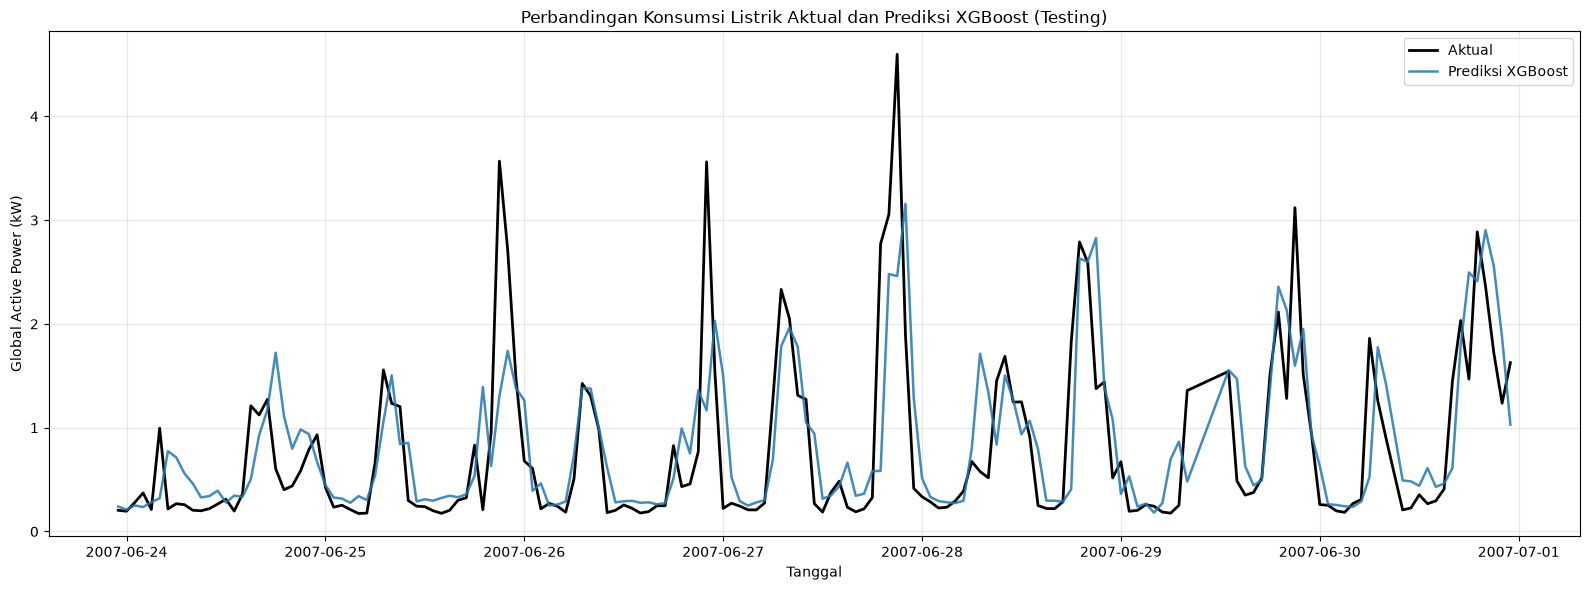

In [45]:
data_plot = pd.concat([
    test_actual.rename("Actual"),
    test_pred.rename("XGBoost")
], axis=1).sort_index().dropna()

if data_plot.empty:
    raise ValueError("Tidak ada data testing Actual dan XGBoost yang lengkap untuk diplot.")

# Ambil 7 hari terakhir dari periode testing
end_date = data_plot.index.max()
start_date = end_date - pd.Timedelta(days=7)
data_plot = data_plot.loc[start_date:end_date]

plt.figure(figsize=(16, 6))
plt.plot(
    data_plot.index,
    data_plot["Actual"],
    label="Aktual",
    linewidth=2,
    color="black"
)
plt.plot(
    data_plot.index,
    data_plot["XGBoost"],
    label="Prediksi XGBoost",
    linewidth=1.8,
    color="tab:blue",
    alpha=0.85
)
plt.title("Perbandingan Konsumsi Listrik Aktual dan Prediksi XGBoost (Testing)")
plt.xlabel("Tanggal")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Grafik ini memperlihatkan dua garis: konsumsi listrik yang benar-benar terjadi (Actual) dan angka hasil prediksi XGBoost. Grafik menampilkan tujuh hari terakhir dari data Testing agar garisnya lebih mudah dibaca.

Meski XGBoost paling baik di antara tiga model yang dicoba, XGBoost tidak selalu benar pada setiap jam. Ada beberapa waktu yang memiliki selisih prediksi yang besar. Karena tujuan project ini adalah membandingkan model, hasil MAE, RMSE sudah memberikan dasar untuk menentukan model terbaik pada periode penelitian.

## Hasil Forecasting

In [46]:
# 1. Data historis asli per jam
count_hourly = power_raw.resample("h").count()

historical = (
    power_raw.resample("h").mean()
    .where(count_hourly == 60)
    .asfreq("h")
    .sort_index()
)

# 2. Latih ulang model terbaik dengan seluruh histori
features_all = create_features(historical)

training_all = features_all.dropna(
    subset=["target"] + feature_cols
)

future_model = clone(best_xgb_model)

future_model.fit(
    training_all[feature_cols],
    training_all["target"]
)

# Forecast 1 bulan penuh (Juli 2007)
# 31 hari × 24 jam = 744 jam
forecast_hours = 31 * 24

last_date = historical.last_valid_index()

history_extended = historical.loc[:last_date].copy()

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(hours=1),
    periods=forecast_hours,
    freq="h"
)

predictions_future = []

for timestamp in future_dates:

    row = {
        f"lag_{lag}": history_extended.get(
            timestamp - pd.Timedelta(hours=lag),
            np.nan
        )
        for lag in [1, 2, 3, 24]
    }

    row["hour"] = timestamp.hour
    row["day_of_week"] = timestamp.dayofweek
    row["is_weekend"] = int(timestamp.dayofweek >= 5)

    X_future = pd.DataFrame(
        [row],
        index=[timestamp]
    )[feature_cols]

    if X_future.isna().any().any():
        raise ValueError(
            f"Fitur lag tidak lengkap pada {timestamp}"
        )

    prediction = max(
        0.0,
        float(future_model.predict(X_future)[0])
    )

    predictions_future.append(prediction)

    # Hasil prediksi menjadi histori untuk jam berikutnya
    history_extended.loc[timestamp] = prediction

# 4. Series hasil future forecast
future_forecast = pd.Series(
    predictions_future,
    index=future_dates,
    name="Future_Forecast"
)

print("Mulai forecast :", future_forecast.index.min())
print("Akhir forecast :", future_forecast.index.max())
print("Jumlah jam     :", len(future_forecast))

display(future_forecast.head(10))

Mulai forecast : 2007-07-01 00:00:00
Akhir forecast : 2007-07-31 23:00:00
Jumlah jam     : 744


2007-07-01 00:00:00    1.271188
2007-07-01 01:00:00    0.681084
2007-07-01 02:00:00    0.358578
2007-07-01 03:00:00    0.377598
2007-07-01 04:00:00    0.428631
2007-07-01 05:00:00    0.515156
2007-07-01 06:00:00    1.392420
2007-07-01 07:00:00    1.730189
2007-07-01 08:00:00    1.652358
2007-07-01 09:00:00    1.600110
Freq: h, Name: Future_Forecast, dtype: float64

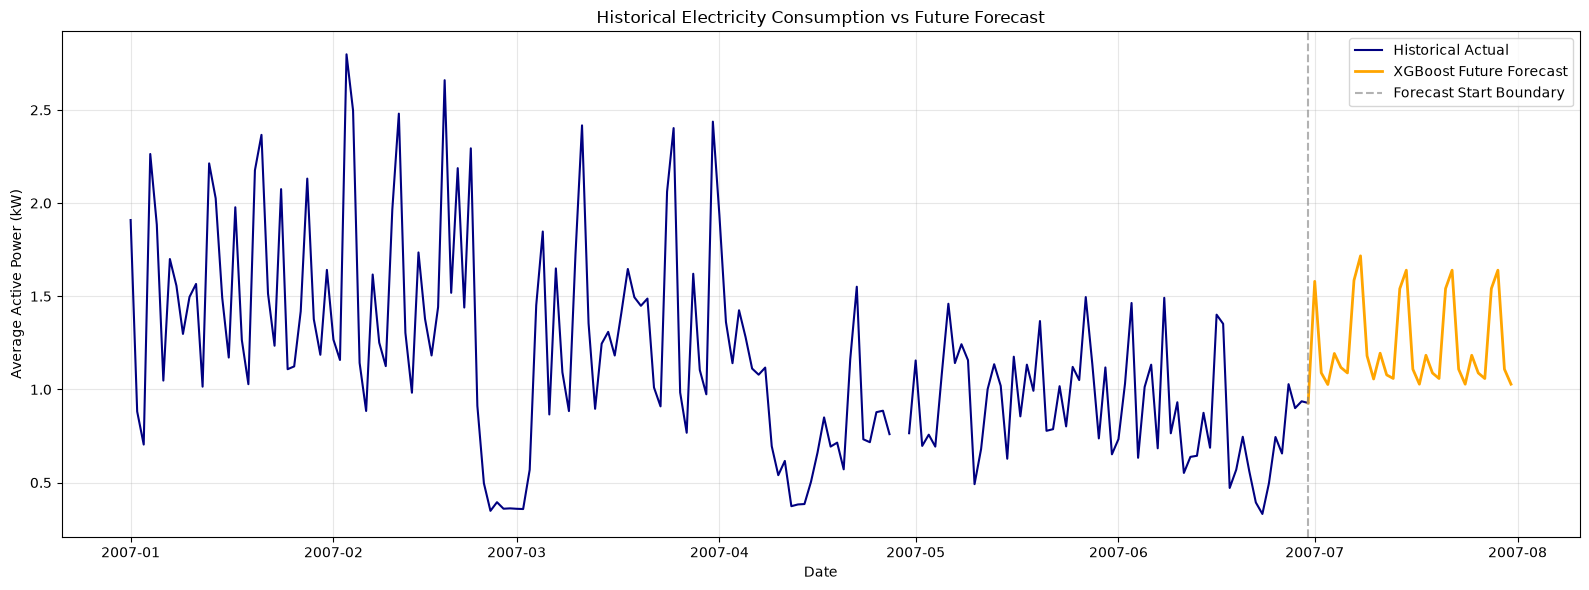

File CSV berhasil dibuat.
Titik penghubung: 2007-06-30 00:00:00
Jumlah hari historis: 179
Jumlah hari forecast: 31

Preview data akhir:


,Historical_Actual,Future_Forecast
Datetime,,
2007-07-20,NaN,1.058464
2007-07-21,NaN,1.541273
2007-07-22,NaN,1.639886
2007-07-23,NaN,1.108554
2007-07-24,NaN,1.028128
2007-07-25,NaN,1.183243
2007-07-26,NaN,1.088227
2007-07-27,NaN,1.058464
2007-07-28,NaN,1.541273


In [47]:
# 1. Gabungkan data historis dan future forecast
full_index = historical.index.union(
    future_forecast.index
).sort_values()

dashboard_data = pd.DataFrame(index=full_index)

dashboard_data["Historical_Actual"] = historical
dashboard_data["Future_Forecast"] = future_forecast

dashboard_data.index.name = "Datetime"


# 2. Tambahkan titik penghubung pada data per jam
last_actual_hour = (
    dashboard_data["Historical_Actual"].last_valid_index()
)

dashboard_data.loc[
    last_actual_hour, "Future_Forecast"
] = dashboard_data.loc[
    last_actual_hour, "Historical_Actual"
]


# 3. Ekspor data per jam
dashboard_data.reset_index().to_csv(
    "historical_future_hourly.csv",
    index=False
)


# 4. Agregasi rata-rata harian
# Mean digunakan karena satuannya kW
dashboard_daily = pd.DataFrame({
    "Historical_Actual": historical.resample("D").mean(),
    "Future_Forecast": future_forecast.resample("D").mean()
}).sort_index()

dashboard_daily.index.name = "Datetime"


# 5. Tambahkan titik penghubung pada data harian
last_actual_day = (
    dashboard_daily["Historical_Actual"].last_valid_index()
)

dashboard_daily.loc[
    last_actual_day, "Future_Forecast"
] = dashboard_daily.loc[
    last_actual_day, "Historical_Actual"
]


# 6. Ekspor data harian untuk grafik utama Power BI
dashboard_daily.reset_index().to_csv(
    "historical_future_daily.csv",
    index=False
)


# 7. Ekspor hasil perbandingan model
final_results.to_csv(
    "model_comparison.csv",
    index=False
)


# 8. Preview grafik historis dan forecast
plt.figure(figsize=(16, 6))

plt.plot(
    dashboard_daily.index,
    dashboard_daily["Historical_Actual"],
    label="Historical Actual",
    color="navy",
    linewidth=1.5
)

plt.plot(
    dashboard_daily.index,
    dashboard_daily["Future_Forecast"],
    label="XGBoost Future Forecast",
    color="orange",
    linewidth=2
)

plt.axvline(
    x=last_actual_day,
    color="gray",
    linestyle="--",
    alpha=0.6,
    label="Forecast Start Boundary"
)

plt.title("Historical Electricity Consumption vs Future Forecast")
plt.xlabel("Date")
plt.ylabel("Average Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 9. Pemeriksaan akhir
print("File CSV berhasil dibuat.")
print("Titik penghubung:", last_actual_day)
print("Jumlah hari historis:", historical.resample("D").count().gt(0).sum())
print("Jumlah hari forecast:", len(future_forecast.resample("D").mean()))
print("\nPreview data akhir:")

display(dashboard_daily.tail(12))

Setelah model terbaik dipilih, proses dilanjutkan dengan membuat perkiraan konsumsi listrik untuk bulan Juli 2007, yaitu periode setelah data historis berakhir. Untuk langkah ini, XGBoost dilatih kembali menggunakan seluruh data historis yang layak digunakan hingga akhir Juni 2007.

# Ekspor Data

Setelah modeling selesai, hasil analisis disimpan sebagai file CSV agar bisa dibaca Power BI. Dengan begitu, Power BI tidak perlu menjalankan ulang pelatihan model dan hanya menampilkan hasil dalam grafik, tabel, dan kartu KPI.

In [52]:
# 1. Mengambil dataset asli
data = df.copy()

# 2. Memastikan index menggunakan datetime
if not isinstance(data.index, pd.DatetimeIndex):

    if "datetime" in data.columns:
        tanggal = pd.to_datetime(
            data["datetime"],
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )
    else:
        tanggal = pd.to_datetime(
            data["Date"].astype(str) + " " +
            data["Time"].astype(str),
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )

    data.index = pd.DatetimeIndex(tanggal)

data = data.loc[data.index.notna()].sort_index()

# 3. Kolom Sub-metering
cols = [
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Ubah menjadi numerik
data[cols] = data[cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# 4. Ambil pengamatan yang lengkap
measured = data.dropna(subset=cols).copy()

# 5. Hitung total energi harian
# Sub-metering dalam Wh -> konversi ke kWh
daily = (
    measured[cols]
    .resample("D")
    .sum(min_count=1)
    / 1000
)

# Hapus tanggal tanpa pengamatan
daily = daily.dropna(how="all")

# # 6. Ubah nama kategori
# daily = daily.rename(columns={
#     "Sub_metering_1": "Dapur",
#     "Sub_metering_2": "Laundry",
#     "Sub_metering_3": "Pemanas Air dan AC"
# })

# 7. Ubah ke format panjang (long format)
submeter_powerbi = (
    daily
    .rename_axis("Datetime")
    .reset_index()
    .melt(
        id_vars="Datetime",
        var_name="Kategori",
        value_name="Energy_kWh"
    )
)

# 8. Ekspor CSV
submeter_powerbi.to_csv(
    "submetering_powerbi.csv",
    index=False
)

# 9. Tampilkan hasil
print("File submetering_powerbi.csv berhasil dibuat.")
print("Jumlah baris:", len(submeter_powerbi))

display(submeter_powerbi.head(12))

File submetering_powerbi.csv berhasil dibuat.
Jumlah baris: 540


,Datetime,Kategori,Energy_kWh
0,2007-01-01,Sub_metering_1,0.000
1,2007-01-02,Sub_metering_1,0.000
2,2007-01-03,Sub_metering_1,0.000
3,2007-01-04,Sub_metering_1,1.051
4,2007-01-05,Sub_metering_1,1.483
5,2007-01-06,Sub_metering_1,1.336
6,2007-01-07,Sub_metering_1,1.987
7,2007-01-08,Sub_metering_1,0.000
8,2007-01-09,Sub_metering_1,1.688
9,2007-01-10,Sub_metering_1,0.771


In [49]:
# Ambil data aktual dan prediksi XGBoost
actual_vs_xgboost = comparison_test[
    ["Actual", "XGBoost"]
].copy().dropna().sort_index()

# Jadikan Datetime sebagai kolom
actual_vs_xgboost.index.name = "Datetime"
actual_vs_xgboost = actual_vs_xgboost.reset_index()

# Ekspor untuk Power BI
actual_vs_xgboost.to_csv(
    "actual_vs_xgboost_powerbi.csv",
    index=False
)

print("CSV berhasil dibuat")
print("Jumlah data:", len(actual_vs_xgboost))

display(actual_vs_xgboost.head(10))

CSV berhasil dibuat
Jumlah data: 835


,Datetime,Actual,XGBoost
0,2007-05-25 19:00:00,2.872733,2.383447
1,2007-05-25 20:00:00,3.573267,2.745901
2,2007-05-25 21:00:00,4.474733,2.988496
3,2007-05-25 22:00:00,1.980967,2.680135
4,2007-05-25 23:00:00,0.306833,1.310510
5,2007-05-26 00:00:00,0.322300,0.543076
6,2007-05-26 01:00:00,0.689100,0.313196
7,2007-05-26 02:00:00,0.493100,0.708032
8,2007-05-26 03:00:00,0.300333,0.562215
9,2007-05-26 04:00:00,0.315167,0.326203
